In [2]:
import matplotlib.pyplot as plt
import multiprocessing as mp
##matplotlib.use('Agg')
import pandas as pd
from sklearn.externals import joblib
import scipy
from itertools import combinations
import numpy as np
import ants
from skimage import measure
import json
import numpy as np
from numpy.testing import assert_raises
from nilearn import datasets, surface, image
from nilearn.plotting import html_surface, html_connectome
from nilearn.plotting.js_plotting_utils import decode
from nilearn.datasets import fetch_surf_fsaverage
from nilearn._utils.exceptions import DimensionError
from matplotlib import gridspec
from nilearn import surface, plotting, datasets
import seaborn as sns
import os, sys
import glob
import json
import os
import copy
from statsmodels.regression.linear_model import OLS
from sklearn.linear_model import Lasso, logistic, LinearRegression, \
LogisticRegression, RidgeClassifier, RidgeClassifierCV
from sklearn.svm import SVR, SVC
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
import xgboost
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, roc_auc_score, average_precision_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler, LabelBinarizer, RobustScaler
from sklearn.feature_selection import SelectFromModel, f_regression, SelectKBest, SelectPercentile, SelectFwe, \
  f_classif, SelectFdr
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, LeaveOneOut, KFold, RepeatedStratifiedKFold, RepeatedKFold
from scipy import stats
from shutil import copyfile
import numpy as np
import pandas as pd
import nibabel as nb

import xgboost as xgb
from imblearn.over_sampling import ADASYN, SMOTE, RandomOverSampler
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics.scorer import make_scorer
sns.set("paper", font_scale=2)
sns.set_style('ticks', {'font.family':'sans-serif', 'font.serif':'Helvetica'})
%matplotlib inline
%reload_ext rpy2.ipython
%lsmagic

/home/qinqian/.local/lib/python3.6/site-packages/sklearn/externals/joblib/__init__.py:15: DeprecationWarning: sklearn.externals.joblib is deprecated in 0.21 and will be removed in 0.23. Please import this functionality directly from joblib, which can be installed with: pip install joblib. If this warning is raised when loading pickled models, you may need to re-serialize those models with scikit-learn 0.21+.
  warnings.warn(msg, category=DeprecationWarning)
Using TensorFlow backend.


Limited tf.compat.v2.summary API due to missing TensorBoard installation
Limited tf.summary API due to missing TensorBoard installation


Available line magics:
%R  %Rdevice  %Rget  %Rpull  %Rpush  %alias  %alias_magic  %autocall  %automagic  %autosave  %bookmark  %cat  %cd  %clear  %colors  %config  %connect_info  %cp  %debug  %dhist  %dirs  %doctest_mode  %ed  %edit  %env  %gui  %hist  %history  %killbgscripts  %ldir  %less  %lf  %lk  %ll  %load  %load_ext  %loadpy  %logoff  %logon  %logstart  %logstate  %logstop  %ls  %lsmagic  %lx  %macro  %magic  %man  %matplotlib  %mkdir  %more  %mv  %notebook  %page  %pastebin  %pdb  %pdef  %pdoc  %pfile  %pinfo  %pinfo2  %popd  %pprint  %precision  %profile  %prun  %psearch  %psource  %pushd  %pwd  %pycat  %pylab  %qtconsole  %quickref  %recall  %rehashx  %reload_ext  %rep  %rerun  %reset  %reset_selective  %rm  %rmdir  %run  %save  %sc  %set_env  %store  %sx  %system  %tb  %time  %timeit  %unalias  %unload_ext  %who  %who_ls  %whos  %xdel  %xmode

Available cell magics:
%%!  %%HTML  %%R  %%SVG  %%bash  %%capture  %%debug  %%file  %%html  %%javascript  %%js  %%latex  %%markdown  

In [3]:
jhu_df = pd.read_csv('jhu_roi_model_raw_fillna.csv')
peaktsb = pd.read_csv('peak_tsb.txt', sep='\t')
final = jhu_df.merge(peaktsb, left_on='participant_id', right_on='participant_id')

outcomes_continue = ['Cognitive_12m', 'Fine Motor_12m',
       'Gross Motor_12m', 'Receptive Communication_12m',
       'Expressive Communication_12m', 'Cognitive_18m', 'Fine Motor_18m',
       'Gross Motor_18m', 'Receptive Communication_18m',
       'Expressive Communication_18m']

response = final.loc[:, outcomes_continue]
brain_markers = final.loc[:, list(final.columns[1:(122*9+1)])+['BEAP', 'Peak-TSB', 'GA', 'CGA', 'bw', 'sex']]
brain_markers.columns[:-5]

Index(['JAC_corpus callosum_left', 'MD_corpus callosum_left',
       'ALFF_corpus callosum_left', 'fALFF_corpus callosum_left',
       'ReHo_corpus callosum_left', 'FA_corpus callosum_left',
       'OD_corpus callosum_left', 'ICVF_corpus callosum_left',
       'ISOVF_corpus callosum_left', 'JAC_corpus callosum_right',
       ...
       'JAC_insular cortex_right', 'MD_insular cortex_right',
       'ALFF_insular cortex_right', 'fALFF_insular cortex_right',
       'ReHo_insular cortex_right', 'FA_insular cortex_right',
       'OD_insular cortex_right', 'ICVF_insular cortex_right',
       'ISOVF_insular cortex_right', 'BEAP'],
      dtype='object', length=1099)

In [50]:
(jhu_df.participant_id == final.participant_id).sum()

174

In [1]:
# final = pd.read_csv('174_connectome.csv')
# response = final.loc[:, outcomes_continue]
# features_list = [list(filter(lambda x:x.startswith('fALFF'), features.columns[:9*122])),
#     list(filter(lambda x:x.startswith('ALFF'), features.columns[:9*122])),
#     list(filter(lambda x:x.startswith('ReHo'), features.columns[:9*122])),
#     list(filter(lambda x:x.startswith('FA'), features.columns[:9*122])),
#     list(filter(lambda x:x.startswith('MD'), features.columns[:9*122])),
#     list(filter(lambda x:x.startswith('JAC'), features.columns[:9*122])),
#     list(filter(lambda x:x.startswith('OD'), features.columns[:9*122])),
#     list(filter(lambda x:x.startswith('ISOVF'), features.columns[:9*122])),
#     list(filter(lambda x:x.startswith('ICVF'), features.columns[:9*122]))]

# all_connectome_features = list(final.columns[:(9*122)]) + list(final.columns[-49729:])
# brain_markers = final.loc[:, all_connectome_features]

# Effect of Peak-TSB

In [3]:
tsb_group = final.loc[:, outcomes_continue]
tsb_group.loc[:, 'Peak_TSB'] = final.loc[:, 'Peak-TSB']
tsb_group.loc[:, 'GA'] = final.loc[:, 'GA']
tsb_group.loc[:, 'CGA'] = final.loc[:, 'CGA']
tsb_group.loc[:, 'BW'] = final.loc[:, 'bw']
#tsb_group1 = tsb_group.loc[tsb_group.GA_Group == 1, :]
#tsb_group2 = tsb_group.loc[tsb_group.GA_Group == 0, :]
#tsb_group1.drop(['GA_Group'])
tsb_group = tsb_group.melt(id_vars=['Peak_TSB', 'CGA', 'GA', 'BW'], value_name='Follow up')
%Rpush tsb_group
%R colnames(tsb_group)[5] = 'Outcome'
%R tsb_group$Time = factor(apply(matrix(tsb_group$Outcome), 1, function(x) unlist(strsplit(x, '_'))[2]))
%R tail(tsb_group)

,Peak_TSB,CGA,GA,BW,Outcome,Follow.up,Time
1734,25.5,39.861429,38.29,3500.0,Expressive Communication_18m,92,18m
1735,22.1,35.140000,32.14,1550.0,Expressive Communication_18m,134,18m
1736,32.4,32.852857,32.71,2030.0,Expressive Communication_18m,97,18m
1737,27.8,53.000000,41.00,3300.0,Expressive Communication_18m,126,18m
1738,33.8,33.710000,29.71,1500.0,Expressive Communication_18m,138,18m
1739,27.0,49.430000,37.43,2910.0,Expressive Communication_18m,119,18m


In [4]:
%%R
library(ggplot2)
library(ggpubr)
print(head(tsb_group))
#print(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))))
ggscatter(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))),
          x = "Peak_TSB", y = "Follow.up", add = "reg.line",
          conf.int = TRUE) +
  facet_wrap(~Time+Outcome, ncol=5) +
  stat_cor(label.x = 20, label.y = 152, method='pearson') +
  stat_regline_equation(label.x = 20, label.y = 160)
#p = ggboxplot(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))), 
#              x='TSB_Group',
#              y='Follow.up', palette = "npg",
#              color='TSB_Group', short.panel.labs = FALSE,
#              add="jitter") + facet_wrap(~ Time + Outcome, ncol=5)
#p + stat_compare_means(method='t.test')
ggsave("Fig2_TSB_linear.pdf", width=13, height=8)

W0717 09:07:32.609459 140130372953856 callbacks.py:116] R[write to console]: Loading required package: magrittr



  Peak_TSB      CGA    GA   BW       Outcome Follow.up Time
0     15.3 41.14000 38.14 3680 Cognitive_12m        96  12m
1     22.1 34.99714 34.14 2265 Cognitive_12m       104  12m
2     30.1 38.29000 30.29  940 Cognitive_12m       122  12m
3     15.4 35.00000 34.00 2220 Cognitive_12m       108  12m
4     19.3 34.43143 32.86 2380 Cognitive_12m        77  12m
5     21.5 35.14286 33.00 2050 Cognitive_12m        77  12m


In [5]:
%%R
library(ggplot2)
library(ggpubr)
print(head(tsb_group))
#print(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))))
ggscatter(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))),
          x = "GA", y = "Follow.up", add = "reg.line",
          conf.int = TRUE) +
  facet_wrap(~Time+Outcome, ncol=5) +
  stat_cor(label.x = 31, label.y = 152, method='pearson') +
  stat_regline_equation(label.x = 31, label.y = 160)
#p = ggboxplot(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))), 
#              x='TSB_Group',
#              y='Follow.up', palette = "npg",
#              color='TSB_Group', short.panel.labs = FALSE,
#              add="jitter") + facet_wrap(~ Time + Outcome, ncol=5)
#p + stat_compare_means(method='t.test')
ggsave("Fig2_GA_linear.pdf", width=13, height=8)

  Peak_TSB      CGA    GA   BW       Outcome Follow.up Time
0     15.3 41.14000 38.14 3680 Cognitive_12m        96  12m
1     22.1 34.99714 34.14 2265 Cognitive_12m       104  12m
2     30.1 38.29000 30.29  940 Cognitive_12m       122  12m
3     15.4 35.00000 34.00 2220 Cognitive_12m       108  12m
4     19.3 34.43143 32.86 2380 Cognitive_12m        77  12m
5     21.5 35.14286 33.00 2050 Cognitive_12m        77  12m


In [6]:
%%R
library(ggplot2)
library(ggpubr)
print(head(tsb_group))
#print(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))))
ggscatter(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))),
          x = "CGA", y = "Follow.up", add = "reg.line",
          conf.int = TRUE) +
  facet_wrap(~Time+Outcome, ncol=5) +
  stat_cor(label.x = 31, label.y = 152, method='pearson') +
  stat_regline_equation(label.x = 31, label.y = 160)
#p = ggboxplot(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))), 
#              x='TSB_Group',
#              y='Follow.up', palette = "npg",
#              color='TSB_Group', short.panel.labs = FALSE,
#              add="jitter") + facet_wrap(~ Time + Outcome, ncol=5)
#p + stat_compare_means(method='t.test')
ggsave("Fig2_CGA_linear.pdf", width=13, height=8)

  Peak_TSB      CGA    GA   BW       Outcome Follow.up Time
0     15.3 41.14000 38.14 3680 Cognitive_12m        96  12m
1     22.1 34.99714 34.14 2265 Cognitive_12m       104  12m
2     30.1 38.29000 30.29  940 Cognitive_12m       122  12m
3     15.4 35.00000 34.00 2220 Cognitive_12m       108  12m
4     19.3 34.43143 32.86 2380 Cognitive_12m        77  12m
5     21.5 35.14286 33.00 2050 Cognitive_12m        77  12m


In [7]:
%%R
library(ggplot2)
library(ggpubr)
print(head(tsb_group))
#print(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))))
ggscatter(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))),
          x = "BW", y = "Follow.up", add = "reg.line",
          conf.int = TRUE) +
  facet_wrap(~Time+Outcome, ncol=5) +
  stat_cor(label.x = 31, label.y = 152, method='pearson') +
  stat_regline_equation(label.x = 31, label.y = 160)
#p = ggboxplot(subset(tsb_group, (!(Outcome %in% c("CGA", "BW", "GA", "Peak_TSB")))), 
#              x='TSB_Group',
#              y='Follow.up', palette = "npg",
#              color='TSB_Group', short.panel.labs = FALSE,
#              add="jitter") + facet_wrap(~ Time + Outcome, ncol=5)
#p + stat_compare_means(method='t.test')
ggsave("Fig2_BW_linear.pdf", width=13, height=8)

  Peak_TSB      CGA    GA   BW       Outcome Follow.up Time
0     15.3 41.14000 38.14 3680 Cognitive_12m        96  12m
1     22.1 34.99714 34.14 2265 Cognitive_12m       104  12m
2     30.1 38.29000 30.29  940 Cognitive_12m       122  12m
3     15.4 35.00000 34.00 2220 Cognitive_12m       108  12m
4     19.3 34.43143 32.86 2380 Cognitive_12m        77  12m
5     21.5 35.14286 33.00 2050 Cognitive_12m        77  12m


In [8]:
tsb_group = final.loc[:, outcomes_continue]
tsb_group.loc[:, 'TSB_Group'] = 'Medium'
tsb_group.loc[(final.loc[:, 'Peak-TSB'] >= 15) & (final.loc[:, 'Peak-TSB'] < 20), 'TSB_Group'] = 'Severe'
tsb_group.loc[:, 'GA_Group'] = 'Preterm'
tsb_group.loc[final.GA > 35, 'GA_Group'] = '(Near) Term'

tsb_group.loc[:, 'VLBW'] = 0
tsb_group.loc[final.bw < 1500, 'VLBW'] = 1

#tsb_group1 = tsb_group.loc[tsb_group.GA_Group == 1, :]
#tsb_group2 = tsb_group.loc[tsb_group.GA_Group == 0, :]
#tsb_group1.drop(['GA_Group'])
tsb_group = tsb_group.melt(id_vars=['TSB_Group', 'GA_Group', 'VLBW'], value_name='Follow up')
%Rpush tsb_group
%R colnames(tsb_group)[4] = 'Outcome'
%R tsb_group$Time = factor(apply(matrix(tsb_group$Outcome), 1, function(x) unlist(strsplit(x, '_'))[4]))
%R tail(tsb_group)

,TSB_Group,GA_Group,VLBW,Outcome,Follow.up,Time
1734,Medium,(Near) Term,0,Expressive Communication_18m,92,NaN
1735,Medium,Preterm,0,Expressive Communication_18m,134,NaN
1736,Medium,Preterm,0,Expressive Communication_18m,97,NaN
1737,Medium,(Near) Term,0,Expressive Communication_18m,126,NaN
1738,Medium,Preterm,0,Expressive Communication_18m,138,NaN
1739,Medium,(Near) Term,0,Expressive Communication_18m,119,NaN


In [9]:
%%R
print(head(tsb_group))
library(ggplot2)
library(ggpubr)
p = ggboxplot(subset(tsb_group, (!(Outcome %in% c("CGA", "GA", "Peak-TSB")))), 
              x='TSB_Group',
              y='Follow.up', palette = "npg",
              color='TSB_Group', short.panel.labs = FALSE,
              add="jitter") + facet_wrap(~ Time + Outcome, ncol=5)
p + stat_compare_means(method='t.test')
ggsave("Fig2_TSB.pdf", width=13, height=12)

  TSB_Group    GA_Group VLBW       Outcome Follow.up Time
0    Severe (Near) Term    0 Cognitive_12m        96 <NA>
1    Medium     Preterm    0 Cognitive_12m       104 <NA>
2    Medium     Preterm    1 Cognitive_12m       122 <NA>
3    Severe     Preterm    0 Cognitive_12m       108 <NA>
4    Severe     Preterm    0 Cognitive_12m        77 <NA>
5    Medium     Preterm    0 Cognitive_12m        77 <NA>


## Preterm or not

In [10]:
%%R
print(head(tsb_group))
library(ggplot2)
library(ggpubr)
p = ggboxplot(subset(tsb_group, (!(Outcome %in% c("CGA", "GA", "Peak-TSB")))), 
              x='GA_Group',
              y='Follow.up', palette = "npg",
              color='GA_Group', short.panel.labs = FALSE,
              add="jitter") + facet_wrap(~ Time + Outcome, ncol=5)
p + stat_compare_means(method='t.test')
ggsave("Fig2_Preterm.pdf", width=13, height=12)

  TSB_Group    GA_Group VLBW       Outcome Follow.up Time
0    Severe (Near) Term    0 Cognitive_12m        96 <NA>
1    Medium     Preterm    0 Cognitive_12m       104 <NA>
2    Medium     Preterm    1 Cognitive_12m       122 <NA>
3    Severe     Preterm    0 Cognitive_12m       108 <NA>
4    Severe     Preterm    0 Cognitive_12m        77 <NA>
5    Medium     Preterm    0 Cognitive_12m        77 <NA>


In [11]:
%%R
print(head(tsb_group))
library(ggplot2)
library(ggpubr)
p = ggboxplot(subset(tsb_group, (!(Outcome %in% c("CGA", "GA", "Peak-TSB")))), 
              x='VLBW',
              y='Follow.up', palette = "npg",
              color='VLBW', short.panel.labs = FALSE,
              add="jitter") + facet_wrap(~ Outcome, ncol=5)
p + stat_compare_means(method='t.test')
ggsave("Fig2_VLBW.pdf", width=13, height=12)

  TSB_Group    GA_Group VLBW       Outcome Follow.up Time
0    Severe (Near) Term    0 Cognitive_12m        96 <NA>
1    Medium     Preterm    0 Cognitive_12m       104 <NA>
2    Medium     Preterm    1 Cognitive_12m       122 <NA>
3    Severe     Preterm    0 Cognitive_12m       108 <NA>
4    Severe     Preterm    0 Cognitive_12m        77 <NA>
5    Medium     Preterm    0 Cognitive_12m        77 <NA>


In [12]:
%%R
a = tsb_group[with(tsb_group, TSB_Group=='Medium' & GA_Group=='Preterm' & Outcome=='Expressive Communication_18m'), 'Follow.up']
b = tsb_group[with(tsb_group, TSB_Group=='Severe' & GA_Group=='Preterm' & Outcome=='Expressive Communication_18m'), 'Follow.up']
cat(length(a), length(b))
print(t.test(a, b))

66 21
	Welch Two Sample t-test

data:  a and b
t = -1.7359, df = 36.571, p-value = 0.091
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -21.977108   1.700052
sample estimates:
mean of x mean of y 
 97.57576 107.71429 



In [13]:
baep_analysis = final.loc[:, ['BEAP', 'GA', 'CGA','Peak-TSB']+outcomes_continue]

In [14]:
## https://zhuanlan.zhihu.com/p/27491381
baep_analysis.loc[:, 'TSB_Group'] = 'Medium'
baep_analysis.loc[~(baep_analysis.loc[:, 'Peak-TSB'] >= 15) & (baep_analysis.loc[:, 'Peak-TSB'] < 20), 'TSB_Group'] = 'Severe'
baep_analysis.loc[:, 'GA_Group'] = 'Preterm'
baep_analysis.loc[final.GA > 35, 'GA_Group'] = '(Near) Term'
baep_analysis = baep_analysis.loc[~pd.isnull(baep_analysis.BEAP), ]
baep_analysis_melt = baep_analysis.melt(id_vars=['BEAP', 'TSB_Group', 'GA_Group'], value_name='Follow up')
print(baep_analysis_melt.head())

%Rpush baep_analysis_melt
%R baep_analysis_melt$BEAP = as.factor(baep_analysis_melt$BEAP)
%R colnames(baep_analysis_melt)[4] = 'Outcome'
%R baep_analysis_melt$Time = factor(apply(matrix(baep_analysis_melt$Outcome), 1, function(x) unlist(strsplit(x, '_'))[2]))                                          
%R baep_analysis_melt$Time = factor(baep_analysis_melt$Time, levels=unique(baep_analysis_melt$Time))

   BEAP TSB_Group GA_Group variable  Follow up
0   0.0    Medium  Preterm       GA      34.14
1   1.0    Medium  Preterm       GA      30.29
2   0.0    Medium  Preterm       GA      32.86
3   0.0    Medium  Preterm       GA      33.00
4   0.0    Medium  Preterm       GA      34.29


[NaN, NaN, NaN, NaN, NaN, ..., 18m, 18m, 18m, 18m, 18m]
Length: 1417
Categories (2, object): , 18m]

In [15]:
%%R
library(ggplot2)
library(ggpubr)
p = ggboxplot(subset(baep_analysis_melt, !(Outcome%in% c("GA", "CGA", "Peak-TSB"))), 
              x='BEAP',
              y='Follow.up', palette = "npg",
              color='BEAP', short.panel.labs = FALSE,
              add="jitter") + facet_wrap( ~ Time + Outcome, ncol=5)
p + stat_compare_means(method='t.test') + ylim(c(0,150))
ggsave("Fig2_BEAP.pdf", width=12, height=8)

In [16]:
for i, o in enumerate(outcomes_continue):
    tab = pd.crosstab(final.GA < 35, final[outcomes_continue[i]] < 75)
    print(tab, stats.fisher_exact(tab, alternative='less'))

Cognitive_12m  False  True 
GA                         
False             74     17
True              77      6 (0.3391902215431627, 0.021210130297603)
Fine Motor_12m  False  True 
GA                          
False              80     11
True               70     13 (1.3506493506493507, 0.8167344428047182)
Gross Motor_12m  False  True 
GA                           
False               78     13
True                76      7 (0.5526315789473685, 0.16596480521568707)
Receptive Communication_12m  False  True 
GA                                       
False                           79     12
True                            73     10 (0.9018264840182648, 0.5021096436608764)
Expressive Communication_12m  False  True 
GA                                        
False                            85      6
True                             73     10 (1.9406392694063928, 0.9344769945272803)
Cognitive_18m  False  True 
GA                         
False             78     13
True              73   

In [17]:
for i in response.columns[response.columns.str.contains('12m')]:
    for j in response.columns[response.columns.str.contains('18m')]:
        co = stats.spearmanr(response.loc[:, i], response.loc[:, j])
        print(i, j, co[0], co[1])

Cognitive_12m Cognitive_18m 0.7205660514944964 3.726779111955619e-29
Cognitive_12m Fine Motor_18m 0.8250106538185253 1.712950105331813e-44
Cognitive_12m Gross Motor_18m 0.8459383489109156 7.791645121457902e-49
Cognitive_12m Receptive Communication_18m 0.6768022192129217 1.1746158980212742e-24
Cognitive_12m Expressive Communication_18m 0.536415654293136 2.3707831044225918e-14
Fine Motor_12m Cognitive_18m 0.6295635245089034 1.3436797209066209e-20
Fine Motor_12m Fine Motor_18m 0.6668981602848335 9.599018753852705e-24
Fine Motor_12m Gross Motor_18m 0.7151769484089878 1.481863924918026e-28
Fine Motor_12m Receptive Communication_18m 0.5631827991184963 6.001968566650944e-16
Fine Motor_12m Expressive Communication_18m 0.4343594897385791 2.121395628309552e-09
Gross Motor_12m Cognitive_18m 0.6317869974762506 8.971734497208674e-21
Gross Motor_12m Fine Motor_18m 0.6913702419955333 4.5848665513399937e-26
Gross Motor_12m Gross Motor_18m 0.7542309672874765 3.0266818884828243e-33
Gross Motor_12m Recep

In [18]:
for j in response.columns[response.columns.str.contains('18m')]:
    print(pd.crosstab((final.GA<37) & (final.loc[:, 'Peak-TSB']>15) & (final.loc[:, 'Peak-TSB']<=20), response.loc[:, j]<80))

Cognitive_18m  False  True 
row_0                      
False            117     31
True              25      1
Fine Motor_18m  False  True 
row_0                       
False             125     23
True               22      4
Gross Motor_18m  False  True 
row_0                        
False              127     21
True                21      5
Receptive Communication_18m  False  True 
row_0                                    
False                          120     28
True                            25      1
Expressive Communication_18m  False  True 
row_0                                     
False                           109     39
True                             23      3


In [4]:
class SelectP(SelectFdr):
    def __init__(self, score_func, alpha):
        super().__init__(score_func, alpha)
        
    def _get_support_mask(self):
        return self.pvalues_ <= self.alpha  # similar strategy as STM autism

In [5]:
response.columns = response.columns.map(lambda x:x.replace(' ', '_').replace('-', '_'))
features = brain_markers
# if 'Cog' in outcome:
#      cutoff = 75
# elif 'Motor' in outcome:
#      cutoff = 76
# else:
#      cutoff = 74 # language
cog = ((response.loc[:, ['Cognitive_12m', 'Cognitive_18m']] < 85).sum(axis=1) >= 1).astype(int)
lan = ((response.loc[:, ['Receptive_Communication_12m', 'Receptive_Communication_18m', 
                         'Expressive_Communication_12m', 'Expressive_Communication_18m']] < 85).sum(axis=1) >= 1).astype(int)
mot = ((response.loc[:, ['Fine_Motor_12m', 'Fine_Motor_18m', 
                         'Gross_Motor_12m', 'Gross_Motor_18m']] < 85).sum(axis=1) >= 1).astype(int)
# cog12 = ((response.loc[:, ['Cognitive_12m']] < 75).sum(axis=1) >= 1).astype(int)
# cog18 = ((response.loc[:, ['Cognitive_18m']] < 75).sum(axis=1) >= 1).astype(int)

# lan12 = ((response.loc[:, ['Receptive_Communication_12m', 
#                            'Expressive_Communication_12m']] < 74).sum(axis=1) >= 1).astype(int)
# lan18 = ((response.loc[:, ['Receptive_Communication_18m','Expressive_Communication_18m']]<74).sum(axis=1)>=1).astype(int)

# mot12 = ((response.loc[:, ['Fine_Motor_12m', 
#                            'Gross_Motor_12m']] < 76).sum(axis=1) >= 1).astype(int)
# mot18 = ((response.loc[:, ['Fine_Motor_18m', 
#                            'Gross_Motor_18m']] < 76).sum(axis=1) >= 1).astype(int)

cog12 = ((response.loc[:, ['Cognitive_12m']] < 85).sum(axis=1) >= 1).astype(int)
cog18 = ((response.loc[:, ['Cognitive_18m']] < 85).sum(axis=1) >= 1).astype(int)

lan12 = ((response.loc[:, ['Receptive_Communication_12m', 
                           'Expressive_Communication_12m']] < 85).sum(axis=1) >= 1).astype(int)
lan18 = ((response.loc[:, ['Receptive_Communication_18m','Expressive_Communication_18m']]<85).sum(axis=1)>=1).astype(int)

mot12 = ((response.loc[:, ['Fine_Motor_12m', 
                            'Gross_Motor_12m']] < 85).sum(axis=1) >= 1).astype(int)
mot18 = ((response.loc[:, ['Fine_Motor_18m', 
                            'Gross_Motor_18m']] < 85).sum(axis=1) >= 1).astype(int)

# filter patients by GA
#filters = (final.loc[:, 'Peak-TSB']>=20)
# filters = (final.GA <= 35)
# cog = cog.loc[filters]
# lan = lan.loc[filters]
# mot = mot.loc[filters]
# features = features.loc[filters,:].iloc[:, 1:]
# features.head()

In [5]:
cog12.sum(), lan12.sum(), mot12.sum()

(48, 61, 59)

In [6]:
cog18.sum(), lan18.sum(), mot18.sum()

(45, 62, 50)

In [7]:
pd.crosstab(cog12, cog18)

col_0,0,1
row_0,,
0,112,14
1,17,31


In [8]:
beap_features = brain_markers.loc[~pd.isnull(brain_markers.BEAP), :]
beap = brain_markers.BEAP[~pd.isnull(brain_markers.BEAP)]
beap_features = beap_features.drop('BEAP', axis=1)
beap.sum()/beap.shape[0]
beap.sum()

20.0

In [10]:
from sklearn.metrics import make_scorer
def specificity_loss_func(ground_truth, predictions):
    tp, tn, fn, fp = 0.0,0.0,0.0,0.0
    tn, fp, fn, tp = confusion_matrix(ground_truth, predictions).ravel()
    return tn/(tn+fp)

def fpr_loss_func(ground_truth, predictions):
    tn, fp, fn, tp = confusion_matrix(ground_truth, predictions).ravel()
    return 1.0*fp/(tn+fp)

spec_score = make_scorer(specificity_loss_func, greater_is_better=True)
#fpr_score = make_scorer(fpr_loss_func, greater_is_better=False)
fpr_score = make_scorer(fpr_loss_func, greater_is_better=True)

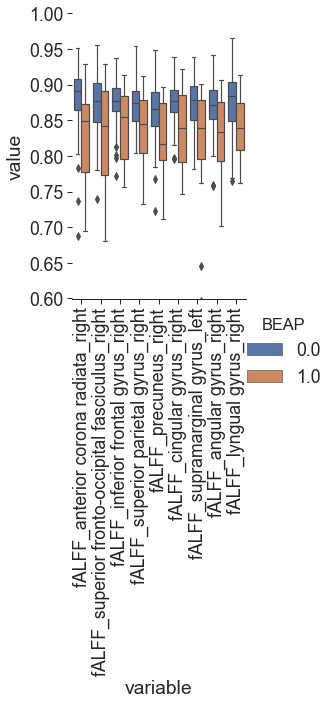

In [11]:
## explore features
from sklearn.model_selection import cross_validate
#from imblearn.pipeline import Pipeline
from sklearn.pipeline import Pipeline
all_perfs = []
select_beap_features = SelectFdr(f_classif, alpha=0.05)
select_beap_features.fit(beap_features, beap)
select_beap_features = select_beap_features.transform(beap_features.columns.values.reshape(1, -1))[0]
select_beap_features = pd.concat([beap_features.loc[:, select_beap_features], beap], axis=1)
select_beap_features.head()

plt.figure(figsize=(18, 10))
g = sns.catplot(x="variable", y='value', data=select_beap_features.melt(id_vars=['BEAP']), hue="BEAP", kind='box')
(g.set_xticklabels(rotation=90)
 .set(ylim=(0.6, 1)).despine(left=True))

In [15]:
features = features.drop('BEAP', axis=1)
features.shape

(174, 1103)

   0                            variable     value modal
0  0  ReHo_anterior corona radiata_right  0.172626  ReHo
1  0  ReHo_anterior corona radiata_right  0.209579  ReHo
2  0  ReHo_anterior corona radiata_right  0.283877  ReHo
3  0  ReHo_anterior corona radiata_right  0.132860  ReHo
4  1  ReHo_anterior corona radiata_right  0.536901  ReHo
   0                   variable     value modal
0  1  ReHo_corpus callosum_left  0.243284  ReHo
1  1  ReHo_corpus callosum_left  0.224003  ReHo
2  1  ReHo_corpus callosum_left  0.312268  ReHo
3  0  ReHo_corpus callosum_left  0.144180  ReHo
4  0  ReHo_corpus callosum_left  0.376161  ReHo
Empty DataFrame
Columns: [0, variable, value, modal]
Index: []


/home/qinqian/.local/lib/python3.6/site-packages/sklearn/feature_selection/base.py:79: UserWarning: No features were selected: either the data is too noisy or the selection test too strict.
  UserWarning)


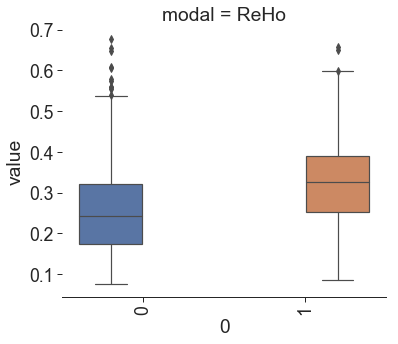

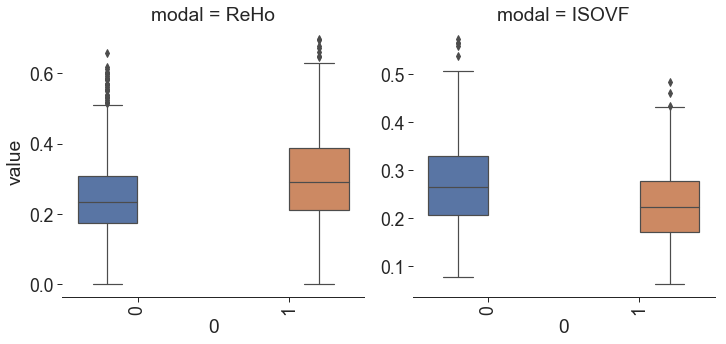

In [30]:
## explore features
from sklearn.model_selection import cross_validate
#from imblearn.pipeline import Pipeline
from sklearn.pipeline import Pipeline
all_perfs = []
for outcome, name in zip([cog, lan, mot], ['Cog', 'Lan', "Mot"]):
    select_outcome_features = SelectFdr(f_classif, alpha=0.05)
    select_outcome_features.fit(features, outcome)
    select_outcome_features = select_outcome_features.transform(beap_features.columns.values.reshape(1, -1))[0]
    select_outcome_features = pd.concat([features.loc[:, select_outcome_features], outcome], axis=1)
    select_outcome_features = select_outcome_features.melt(id_vars=[0])
    select_outcome_features.loc[:, 'modal'] = select_outcome_features.variable.map(lambda x: x.split('_')[0])
    print(select_outcome_features.head())
    if select_outcome_features.shape[0] != 0:
        plt.figure(figsize=(35, 10))
        g = sns.catplot(x=0, y='value', data=select_outcome_features,
                        col='modal', col_wrap=3, sharex=False, sharey=False,
                        hue=0, kind='box')
        (g.set_xticklabels(rotation=90).despine(left=True))
#     .set(ylim=(0.6, 1)).despine(left=True))

In [27]:
?sns.catplot

In [18]:
from sklearn.model_selection import cross_validate
beap_features = beap_features.drop(['BEAP'], axis=1)
#from imblearn.pipeline import Pipeline
from sklearn.pipeline import Pipeline

all_perfs = []
for seed in range(9999, 10000):
    cv = RepeatedStratifiedKFold(5, 10, random_state=seed)
    predictions = []
    print('running cross validation')
    clf = xgb.XGBClassifier(learning_rate=0.1, #reg_lambda=1e-8, reg_alpha=1e-8,
                      n_estimators=10,
                      max_depth=10,
                      min_child_weight = 1,
                      gamma=0.,
                      subsample=0.9,
                      colsample_btree=0.9,
                      objective='binary:logistic',
                      random_state=seed)
    clf = Pipeline([
        ("std", StandardScaler()),
        ("fs",  SelectP(f_classif, alpha=0.05)),
       #("fs",  SelectFdr(f_classif, alpha=0.05)),
        
        #('smote', SMOTE(random_state=seed)),    
    #        ("fs",  SelectKBest(f_classif, k=122)),
        ("clf", clf)
    ])
    params = {
        'clf__n_estimators': [2, 8, 10],
        'clf__max_depth': [2, 8, 10],
        'clf__reg_lambda': scipy.stats.distributions.uniform(1000, 100000)    
    }

    clf1 = Pipeline([
        ("std", StandardScaler()),
        ("fs",  SelectP(f_classif, alpha=0.05)),
      #  ("fs",  SelectFdr(f_classif, alpha=0.05)),
        #('smote', SMOTE(random_state=seed)),
    #        ("fs",  SelectKBest(f_classif, k=122)),
        ("clf", SVC(C=1e8, kernel='linear', probability=True, max_iter=500000, random_state=seed))
    ])    
    params1 = {
    #    'clf__C': [100, 200, 300, 400, 500]
        'clf__C': scipy.stats.distributions.uniform(1000, 100000)        
    }

    clf2 = Pipeline([
        ("std", StandardScaler()),
        ("fs",  SelectP(f_classif, alpha=0.05)),
    #    ("fs",  SelectFdr(f_classif, alpha=0.05)),        
    #        ("fs",  SelectKBest(f_classif, k=122)), 
        #('smote', SMOTE(random_state=seed)),    
        ("clf", LogisticRegression(penalty='l1', solver='liblinear', C=100000000,
                                   max_iter=5000, random_state=seed))
    ])    
    params2 = {
    #    'clf__C': [100, 200, 300, 400, 500]
        'clf__C': scipy.stats.distributions.uniform(1000, 100000)
    } 
    scoring = {'AUC': 'roc_auc', 'Accuracy': 'accuracy', 'PRAUC': make_scorer(average_precision_score, greater_is_better=True),
               "specificity": spec_score, "FPR": fpr_score,
               'f1': 'f1', 'recall': 'recall', 'precision': 'precision'}

    for m, clf, param in zip(['xgboost', 'svm', 'logit'], [clf, clf1, clf2], [params, params1, params2]):    
    #     model = GridSearchCV(clf,  param_grid=param, scoring=scoring, 
    #                          refit='f1', cv=cv, n_jobs=30, return_train_score=True)    
        model = RandomizedSearchCV(clf, param_distributions=param, n_iter=30, cv=cv, refit='f1', n_jobs=30,
                                   scoring=scoring,
                                   return_train_score=True)
        model.fit(beap_features, beap, groups=beap)
        print(model.best_params_)
    #    print(model.cv_results_)
    #     print(model.cv_results_['mean_test_AUC'][model.best_index_])
    #     print(model.cv_results_)    
        model_perf = pd.DataFrame(model.cv_results_)
        model_perf = model_perf.loc[:, model_perf.columns.str.contains('split') & model_perf.columns.str.contains('test')]
        all_perfs.append([m, seed,
                          model.cv_results_['mean_test_AUC'][model.best_index_],
                          model.cv_results_['std_test_AUC'][model.best_index_],
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('AUC')].min(),
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('AUC')].max(),

                          model.cv_results_['mean_test_PRAUC'][model.best_index_],
                          model.cv_results_['std_test_PRAUC'][model.best_index_],
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_PRAUC')].min(),
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_PRAUC')].max(),

                          model.cv_results_['mean_test_f1'][model.best_index_],
                          model.cv_results_['std_test_f1'][model.best_index_],
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_f1')].min(),
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_f1')].max(),

                          model.cv_results_['mean_test_recall'][model.best_index_],
                          model.cv_results_['std_test_recall'][model.best_index_],
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_recall')].min(),
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_recall')].max(),  

                          model.cv_results_['mean_test_precision'][model.best_index_],
                          model.cv_results_['std_test_precision'][model.best_index_],
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_precision')].min(),
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_precision')].max(),

                          model.cv_results_['mean_test_Accuracy'][model.best_index_],
                          model.cv_results_['std_test_Accuracy'][model.best_index_],
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_Accuracy')].min(),
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_Accuracy')].max(),

                          model.cv_results_['mean_test_specificity'][model.best_index_],
                          model.cv_results_['std_test_specificity'][model.best_index_],
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_specificity')].min(),
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_specificity')].max(),

                          model.cv_results_['mean_test_FPR'][model.best_index_],
                          model.cv_results_['std_test_FPR'][model.best_index_],
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_FPR')].min(),
                          model_perf.iloc[model.best_index_, :].loc[model_perf.columns.str.contains('_FPR')].max()])      

running cross validation
{'clf__max_depth': 10, 'clf__n_estimators': 2, 'clf__reg_lambda': 11352.354118157393}
{'clf__C': 21547.255811994357}
{'clf__C': 7982.483991965127}


In [19]:
cols = ['AUC', 'PRAUC', 'f1', 'recall', 'precision', 'Accuracy', 'specificity', 'FPR']
cols_all = []
for i in cols:
    cols_all.append(i+'_mean')
    cols_all.append(i+'_sd')
    cols_all.append(i+'_min')
    cols_all.append(i+'_max')         
perfs = pd.DataFrame(all_perfs)
perfs.columns = ['method', 'seed'] + cols_all
perfs = perfs.T
perfs

,0,1,2
method,xgboost,svm,logit
seed,9999,9999,9999
AUC_mean,0.612696,0.515327,0.530964
AUC_sd,0.173023,0.166379,0.158909
AUC_min,0.17803,0.164141,0.167614
AUC_max,1,0.888889,0.930556
PRAUC_mean,0.271589,0.227746,0.231931
PRAUC_sd,0.125939,0.0761424,0.0771199
PRAUC_min,0.17803,0.164141,0.167614
PRAUC_max,0.666667,0.5,0.444444


In [12]:
perfs.to_csv("BEAP_performances_5cross_100times.csv")

In [23]:
from imblearn.pipeline import Pipeline
features = brain_markers.drop('BEAP', axis=1)
all_perfs = []
seed = 9999
scoring = {'AUC': 'roc_auc', 'Accuracy': 'accuracy', 'PRAUC': make_scorer(average_precision_score, greater_is_better=True),
           "specificity": spec_score, "FPR": fpr_score,
           'f1': 'f1', 'recall': 'recall', 'precision': 'precision'}
cv = RepeatedStratifiedKFold(5, 3, random_state=seed)
# for outcome, name in zip([cog12, cog18], 
#                          ['Cognition12', 'Cognition18']):
# for outcome, name in zip([cog12, cog18, lan12, lan18, mot12, mot18], 
#                          ['Cognition12', 'Cognition18', 'Language12', 'Language18', 
#                           'Motor12', 'Motor18']):    
for outcome, name in zip([cog, lan, mot],
                         ['Cognition', 'Language', 'Motor']):
    predictions = []
    print('running cross validation')
    clf = xgb.XGBClassifier(learning_rate=0.1, #reg_lambda=1e-8, reg_alpha=1e-8,
                      n_estimators=10,
                      max_depth=10,
                      min_child_weight = 1,
                      gamma=0.,
                      subsample=0.9,
                      colsample_btree=0.9,
                      objective='binary:logistic',
                      random_state=seed)
    clf = Pipeline([
        ("std", RobustScaler()),
        ("fs",  SelectP(f_classif, alpha=0.05)),
#        ("smote", SMOTE(random_state=seed)),        
#        ("fs",  SelectKBest(f_classif, k=122)),
        ("clf", clf)        
    ])
    params = {
        'clf__n_estimators': [2, 8, 10, 20],
        'clf__max_depth': [2, 8, 10, 20],
        #'clf__reg_lambda': [100, 200, 300, 400, 500]
        'clf__reg_lambda': [1e-2, 1e-1, 1, 10, 100]   
    }  
    clf1 = Pipeline([
        ("std", RobustScaler()),
        ("fs",  SelectP(f_classif, alpha=0.05)),
#        ("smote", SMOTE(random_state=seed)),
#        ("fs",  SelectKBest(f_classif, k=122)),
        ("clf", SVC(C=1e8, kernel='linear', probability=True, max_iter=500000, random_state=seed))
    ])    
    params1 = {
        #'clf__C': [100, 200, 300, 400, 500]
        'clf__C': [1e-4, 1e-2, 1, 10, 100, 1000, 100000]        
    }    
    clf2 = Pipeline([
        ("std", RobustScaler()),
        ("fs",  SelectP(f_classif, alpha=0.05)),
#        ("smote", SMOTE(random_state=seed)),        
#        ("fs",  SelectKBest(f_classif, k=122)), 
        ("clf", LogisticRegression(penalty='l1', solver='liblinear', C=100000000,
                                   max_iter=5000, random_state=seed))
    ])    
    params2 = {
#         'clf__C': [100, 200, 300, 400, 500]
        'clf__C': [1e-4, 1e-2, 1, 10, 100, 1000, 100000]
    } 

    for m, clf, param in zip(['xgboost', 'svm', 'logit'], [clf, clf1, clf2], [params, params1, params2]):
        model = GridSearchCV(clf, param_grid=param, scoring=scoring, 
                             refit='f1', cv=cv, n_jobs=30, return_train_score=True)    
        model.fit(features, outcome, groups=outcome)
        print(model.best_estimator_)
        all_perfs.append([m, name, seed, 
                          model.cv_results_['mean_test_AUC'][model.best_index_], 
                          model.cv_results_['mean_test_AUC'].std(),
                          model.cv_results_['mean_test_AUC'].min(),    
                          model.cv_results_['mean_test_AUC'].max(),   

                          model.cv_results_['mean_test_PRAUC'][model.best_index_], 
                          model.cv_results_['mean_test_PRAUC'].std(),
                          model.cv_results_['mean_test_PRAUC'].min(),    
                          model.cv_results_['mean_test_PRAUC'].max(),       

                          model.cv_results_['mean_test_f1'][model.best_index_], 
                          model.cv_results_['mean_test_f1'].std(),
                          model.cv_results_['mean_test_f1'].min(),    
                          model.cv_results_['mean_test_f1'].max(),                            

                          model.cv_results_['mean_test_recall'][model.best_index_], 
                          model.cv_results_['mean_test_recall'].std(),
                          model.cv_results_['mean_test_recall'].min(),    
                          model.cv_results_['mean_test_recall'].max(),        

                          model.cv_results_['mean_test_precision'][model.best_index_], 
                          model.cv_results_['mean_test_precision'].std(),
                          model.cv_results_['mean_test_precision'].min(),    
                          model.cv_results_['mean_test_precision'].max(),     

                          model.cv_results_['mean_test_Accuracy'][model.best_index_], 
                          model.cv_results_['mean_test_Accuracy'].std(),
                          model.cv_results_['mean_test_Accuracy'].min(),    
                          model.cv_results_['mean_test_Accuracy'].max(),     

                          model.cv_results_['mean_test_specificity'][model.best_index_], 
                          model.cv_results_['mean_test_specificity'].std(),
                          model.cv_results_['mean_test_specificity'].min(),    
                          model.cv_results_['mean_test_specificity'].max(),   

                          model.cv_results_['mean_test_FPR'][model.best_index_], 
                          model.cv_results_['mean_test_FPR'].std(),
                          model.cv_results_['mean_test_FPR'].min(),    
                          model.cv_results_['mean_test_FPR'].max()]                     
                        )
#         scores = cross_validate(clf, features, outcome, scoring=scoring, groups=outcome, 
#                                 cv=cv, n_jobs=30, return_train_score=False)
#         all_perfs.append([m,name, seed, np.mean(scores['test_recall']), 
#                           np.mean(scores['test_f1']), 
#                           np.mean(scores['test_auc'])])

running cross validation
running cross validation
running cross validation


In [24]:
cols = ['AUC', 'PRAUC', 'f1', 'recall', 'precision', 'Accuracy', 'specificity', 'FPR']
cols_all = []
for i in cols:
    cols_all.append(i+'_mean')
    cols_all.append(i+'_sd')
    cols_all.append(i+'_min')
    cols_all.append(i+'_max')     
    
perfs = pd.DataFrame(all_perfs)
perfs.columns = ['method', 'outcome', 'seed'] + cols_all
perfs = perfs.T
perfs

,0,1,2,3,4,5,6,7,8
method,xgboost,svm,logit,xgboost,svm,logit,xgboost,svm,logit
outcome,Cognition,Cognition,Cognition,Language,Language,Language,Motor,Motor,Motor
seed,9999,9999,9999,9999,9999,9999,9999,9999,9999
AUC_mean,0.632036,0.546407,0.596582,0.520132,0.570698,0.581137,0.599418,0.510143,0.508235
AUC_sd,0.0229961,0.0222446,0.0307468,0.00738463,0.0128049,0.0325024,0.0146036,0.0398278,0.0129686
AUC_min,0.574253,0.54551,0.5,0.493326,0.559459,0.5,0.548337,0.50153,0.5
AUC_max,0.657849,0.595729,0.596582,0.521871,0.599327,0.581137,0.60531,0.597229,0.539008
PRAUC_mean,0.322656,0.297138,0.30545,0.483671,0.49117,0.493912,0.442813,0.395443,0.396716
PRAUC_sd,0.00735136,0.0074299,0.0104234,0.00672506,0.0103784,0.0133668,0.00852418,0.0154353,0.00717886
PRAUC_min,0.292607,0.275724,0.275724,0.462131,0.459832,0.459832,0.410795,0.384967,0.384967


In [11]:
bold_bad_subs = []
for i in glob.glob('results/processed/*badtimes0.2*'):
    with open(i) as inf:
        if 155-len(inf.readline().strip().split())<=30:
            bold_bad_subs.append(os.path.basename(i).split('_')[0])
bold_bad_subs.append('sub-19')
bold_bad_subs.append('sub-54')
df = pd.read_table('kai_2017_dti_t1_bold_to_be_processed.xls')
df.drop('ID.1', axis=1, inplace=True)
df.loc[pd.isnull(df.ga), 'ga'] = df.ga.mean()
df.loc[pd.isnull(df.age), 'age'] = df.age.mean()
cga = df.ga + df.age
df.loc[:, 'cga'] = cga
df.loc[:, 'sex'] = LabelBinarizer().fit(df.sex).transform(df.sex)
df.loc[pd.isnull(df.bw), 'bw'] = np.median(df.bw[~pd.isnull(df.bw)])

bold_quality = np.ones(df.shape[0])
bold_quality[df.participant_id.isin(bold_bad_subs)] = 0
df.loc[:, 'bold_quality'] = bold_quality
df.loc[:, 'preterm'] = (df.ga < 37).astype(int)
native_fs = pd.read_table('all_files_in_native_space.txt', header=None, delimiter=' ')
native_fs.index = native_fs.loc[:, 0]
native_fs_tmp = df.merge(native_fs, left_on='participant_id', right_index=True)
native_fs_tmp.index = native_fs_tmp.participant_id
native_fs_out = native_fs_tmp.loc[list(native_fs.index), :]

/home/qinqian/.local/lib/python3.6/site-packages/ipykernel_launcher.py:8: FutureWarning: read_table is deprecated, use read_csv instead, passing sep='\t'.
  
/home/qinqian/.local/lib/python3.6/site-packages/ipykernel_launcher.py:21: FutureWarning: read_table is deprecated, use read_csv instead.


In [13]:
(native_fs_out.iloc[native_fs_quality, 0].values == final.iloc[:, 0].values).sum()

174

In [47]:
mask_filename = 'template_mask.nii.gz'
from nilearn.input_data import NiftiMasker
from nilearn.plotting import plot_stat_map
seed = 9999
cv = RepeatedStratifiedKFold(3, 5, random_state=seed)
all_perfs = []
for outcome, name in zip([cog12, cog18, lan12, lan18, mot12, mot18], 
                         ['Cognition12', 'Cognition18', 'Language12', 'Language18', 
                          'Motor12', 'Motor18']):
    for modal in ['od', 'fa', 'reho', 'falff', ]:
        img = f'{modal}_local_template.nii.gz'
        masker = NiftiMasker(mask_img=mask_filename, smoothing_fwhm=6,
                             standardize=True, memory="nilearn_cache", memory_level=1)
        X = masker.fit_transform(img)
        X = X[native_fs_quality]
        print(X.shape)
        svc_k_steps = [
            ('std', StandardScaler()),
            ('fs', SelectPercentile(f_regression, percentile=0.5)),
            ('SVC', SVC(C=1, probability=True, random_state=seed))
        ]
        svc_k_params = {
            'SVC__C': np.linspace(1e-5, 1e4, 10),
            'SVC__kernel': ['linear']
        }
        svc_k_pipe = Pipeline(svc_k_steps)    
    #     cv_scores = cross_val_score(svc_k_pipe, X, 
    #                                 mot18, cv=cv, 
    #                                 groups=mot18, scoring='roc_auc')    
    #     X_train, X_test, y_train, y_test = \
    #     train_test_split(X,
    #                      outcomes,
    #                      random_state=1, 
    #                      test_size=0.3, stratify=outcomes)
        grid = GridSearchCV(svc_k_pipe, param_grid=svc_k_params, cv=cv, scoring='roc_auc', n_jobs=30)
        grid.fit(X, outcome, groups=outcome)
    #     X_test_prediction = grid.predict(X_test) 
    #     X_test_prob = grid.predict_proba(X_test)[:, 1]
    #     print(X_test_prediction.shape, X_test_prob.shape)
        cvres = pd.DataFrame(grid.cv_results_).sort_values('mean_test_score', ascending=False)        
        all_perfs.append(name, modal, cvres.iloc[0, :].loc['mean_test_score'])
    #     # reverse masking
    #     weight_img = masker.inverse_transform(coef)
    #     # Use the mean image as a background to avoid relying on anatomical data
    #     from nilearn import image
    #     mean_img = image.mean_img(img)
    #     # Create the figure    
    #     plot_stat_map(weight_img, mean_img, title=f'{modal} SVM weights')

(174, 536590)


TypeError: append() takes exactly one argument (3 given)

In [40]:
pd.DataFrame(grid.cv_results_).sort_values('mean_test_score', ascending=False).head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_SVC__C,param_SVC__kernel,params,split0_test_score,split1_test_score,split2_test_score,...,split8_test_score,split9_test_score,split10_test_score,split11_test_score,split12_test_score,split13_test_score,split14_test_score,mean_test_score,std_test_score,rank_test_score
0,16.718765,2.011142,1.004806,0.136070,1e-05,linear,"{'SVC__C': 1e-05, 'SVC__kernel': 'linear'}",0.725490,0.316527,0.571429,...,0.507003,0.610644,0.543417,0.619048,0.792717,0.529412,0.602241,0.596078,0.109915,1
37,17.738349,1.352598,0.964965,0.204717,7551.02,linear,"{'SVC__C': 7551.0204106122455, 'SVC__kernel': ...",0.610644,0.313725,0.571429,...,0.778711,0.624650,0.635854,0.512605,0.577031,0.540616,0.663866,0.571802,0.110531,2
27,17.914667,1.362623,1.038555,0.213185,5510.2,linear,"{'SVC__C': 5510.204086122449, 'SVC__kernel': '...",0.610644,0.313725,0.571429,...,0.778711,0.624650,0.635854,0.512605,0.577031,0.540616,0.663866,0.571802,0.110531,2
28,17.099568,1.396569,1.012426,0.222065,5714.29,linear,"{'SVC__C': 5714.285718571428, 'SVC__kernel': '...",0.610644,0.313725,0.571429,...,0.778711,0.624650,0.635854,0.512605,0.577031,0.540616,0.663866,0.571802,0.110531,2
29,17.667887,1.511128,1.132179,0.175899,5918.37,linear,"{'SVC__C': 5918.367351020408, 'SVC__kernel': '...",0.610644,0.313725,0.571429,...,0.778711,0.624650,0.635854,0.512605,0.577031,0.540616,0.663866,0.571802,0.110531,2


In [10]:
cv = LeaveOneOut()
selectp = SelectP(f_classif, alpha=0.05)
svm = Pipeline([
    ("std", RobustScaler()),
    ("clf", SVC(C=1, kernel='linear', probability=True, max_iter=5000))
])
logit100 = LogisticRegression(penalty='elasticnet', l1_ratio=0.5, C=10, solver='saga',
                              class_weight='balanced',
                              max_iter=5000, random_state=999)
logit = Pipeline([
    ("std", RobustScaler()),
    ("clf", logit100)
])
all_outcome_features = []
clf = logit

features = features.drop('BEAP', axis=1)
for outcome, name in zip([cog, lan, mot], ['Cognition', 'Language', 'Motor']):
    predictions = []       
    n = 0
    for train_index, test_index in cv.split(features):           
        X_train_res = features.iloc[train_index, :]
        Y_train_res = outcome.iloc[train_index]
#       smote = SMOTE(random_state=999)        
#       X_train_res, Y_train_res = smote.fit_sample(X_train_res, Y_train_res)
        Fs, pvals = f_classif(X_train_res, Y_train_res)        
#         _, pvals = f_classif(X_train_res, Y_train_res)
#         print(pvals)
        inc_features = features.columns.values[pvals < 0.05]
        clf.fit(X_train_res.loc[:, inc_features], Y_train_res)        
        pred = clf.predict_proba(features.iloc[test_index, :].loc[:, inc_features])
#         print(pred)
#         inc_features = clf.named_steps['fs'].transform(features.columns.values.reshape(1, -1))[0]
#         if n == 0:
#             all_features = set(list(inc_features))
#         else:
#             all_features.intersection(inc_features)
#         n += 1
#         print(pred)
#         print(n)
        #print(len(all_features))
#         clf.fit(X_train_res, Y_train_res)          
#         clf.fit(features.loc[train_index, inc_features], group)  
#         dtrain = xgb.DMatrix(features.loc[train_index, inc_features], group)
#         dtest = xgb.DMatrix(features.loc[test_index, inc_features], response.loc[test_index, outcome]<cutoff)
#         param = {'max_depth': 2, 'eta': 1, 'silent': 1, 'objective': 'binary:logistic'}
#         param['nthread'] = 20
#         param['eval_metric'] = 'error'
#         evallist = [(dtest, 'eval'), (dtrain, 'train')]
#         num_round = 10
#         bst = xgb.train(param, dtrain, num_round) #, evallist)
#         pred = bst.predict(dtest)
#         label = dtest.get_label()         
#         print(pred, label)
#         predictions.append([(pred>0.5).astype(int)[0], label[0]])     
        predictions.append([pred.argmax(1)[0], #  svm.predict(features.loc[test_index, inc_features])[0],
                            outcome.iloc[test_index].values[0]])
    print(name)
    print('-'*10)
    perf = pd.DataFrame(predictions)
    all_outcome_features.append([name, ';'.join(list(all_features)), 
                                 confusion_matrix(perf.iloc[:, 0], perf.iloc[:, 1]).ravel()])

Cognition
----------


NameError: name 'all_features' is not defined

In [384]:
perfs = pd.DataFrame(all_outcome_features)
perfs
print('model', 'sensitivity', 'specificity', 'positive predictive value', 'negative predictive value')

for o, stat in zip(perfs.iloc[:, 0], perfs.iloc[:, 2]):
    tn, fp, fn, tp = stat
    print(o, tp/(fn+tp), tn/(tn+fp), tp/(tp+fp), tn/(tn+fn))

model sensitivity specificity positive predictive value negative predictive value
Cognition 0.26785714285714285 0.711864406779661 0.30612244897959184 0.672
Language 0.5606060606060606 0.75 0.578125 0.7363636363636363
Motor 0.27692307692307694 0.6513761467889908 0.32142857142857145 0.6016949152542372


In [215]:
jhu_annotations = pd.read_csv('../../data/Atlas/jhu_atlas_neonate/label_JHU-neonate-SS_seg.csv', header=None)
jhu_annotations_dict = {}
jhu_annotations_dict2 = {}
template_b0 = ants.image_read('results/processed/sub-143_T1w_noise_corrected_reoriented_enh_b0.nii.gz')
template_mask = template_b0.get_mask()
jhu_atlas = ants.image_read('results/template/JHU_Atlas_JHU_neonate_SS_122parcellation.nii.gz')
jhu_mat = ants.images_to_matrix([jhu_atlas], template_mask)

albert06 = ants.image_read('results/ALBERTs/ALBERT_06-session1/T2/ALBERT_06-session1.nii.gz')
albert06_mask = albert06.get_mask()
jhu_atlas2 = ants.image_read('results/template/ALBERT_06_warp_to_JHU_JHU_neonate_SS_122parcellation.nii.gz')
jhu_mat2 = ants.images_to_matrix([jhu_atlas2], albert06_mask)

for i in range(jhu_annotations.shape[0]):
    jhu_annotations_dict[jhu_annotations.iloc[i, 0]] = '_'.join(jhu_annotations.iloc[i, 1:-1].tolist())
    jhu_annotations_dict2['_'.join(jhu_annotations.iloc[i, 1:-1].tolist())] = jhu_annotations.iloc[i, 0]    
native_modalities = ['tissue_label', 'b0', 't1', 
                     'alff', 'falff', 'reho', 
                     'fa', 'md', 
                     'od', 'icvf', 'isovf']
templates = []
for t in native_modalities:
    templates.append(ants.image_read(glob.glob(f'{t}_mean_template.nii.gz')[0]))
outcome_dict['Cognitive_18m'][modal].iloc[:, 2]
all_corrs_colname_roi_num = [jhu_annotations_dict2[i] for i in all_corrs.index.map(lambda x: x.split('_', 1)[1])]
all_corrs_modals = [ i for i in all_corrs.index.map(lambda x: x.split('_', 1)[0])]
all_corrs = all_corrs.fillna(0)
all_corrs.loc[all_corrs.index.str.contains("ICVF"), :]
all_corrs.shape
modal_activate = {}
for modal_outcome in all_corrs.columns:
    modal_activate[modal_outcome] = {}    
    for col, modal, roi in zip(all_corrs.index, all_corrs_modals, all_corrs_colname_roi_num):
        modal_activate[modal_outcome][modal] = modal_activate[modal_outcome].get(modal, 0) + (jhu_mat == roi)*all_corrs.loc[col, modal_outcome]        
    for modal in np.unique(all_corrs_modals):
        if (modal_activate[modal_outcome][modal] == 0).all(): print(modal_activate[modal_outcome][modal])
        modal_activate[modal_outcome][modal] = ants.matrix_to_images(modal_activate[modal_outcome][modal], 
                                                                     template_mask)[0].crop_image(template_mask)    

In [ ]:
template_over = templates[1].crop_image(template_mask)
gs = gridspec.GridSpec(5, 4,
         wspace=0.0, hspace=0.0,
         top=1.-0.5/(4+1), bottom=0.5/(4+1),
         left=0.5/(5+1), right=1-0.5/(5+1))
n = 0
fig = plt.figure(figsize=(35, 20))
for modal_outcome in all_corrs.columns:
    for modal in np.unique(all_corrs_modals):
        axes = plt.subplot(gs[n])
        if modal_activate[modal_outcome][modal].sum() == 0: 
            continue
        n += 1
        plotting.plot_stat_map(ants.to_nibabel(modal_activate[modal_outcome][modal]), vmax=0.5,
                               title="%s %s" %(modal_outcome, modal), figure=fig, axes=axes,
                               bg_img=ants.to_nibabel(template_over))
plt.savefig('SuppFig2.pdf')

## With only MRI

In [161]:
import statsmodels.api as sm
from sklearn.base import BaseEstimator, RegressorMixin

class SMWrapper(BaseEstimator, RegressorMixin):
    """ A universal sklearn-style wrapper for statsmodels regressors """
    def __init__(self, model_class):
        self.model_class = model_class
        
    def fit(self, X, y):
        xl = '+'.join(list(X.columns))
        yl = y.columns[0]
        self.model_ = smf.ols(f'{yl} ~ {xl}', data=pd.concat([X, y], axis=1))
        self.results_ = self.model_.fit_regularized(L1_wt=1, alpha=1, refit=True)
            
    def predict(self, X):
        return self.results_.predict(X)

In [164]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
response.columns = response.columns.map(lambda x:x.replace(' ', '_').replace('-', '_'))
features = (brain_markers - brain_markers.mean(axis=0))/brain_markers.std(axis=0)    
features.columns = features.columns.map(lambda x:x.replace(' ', '_').replace('-', '_'))

#features = brain_markers
for outcome in response.columns:
    lasso = SMWrapper(smf.ols)
    #lasso.fit(features, response.loc[:, [outcome]])
    #print(lasso.predict(features))
    #result = smf.ols(f'{outcome} ~ {x}', data=combined_tmp)
    #result_fit = result.fit_regularized(L1_wt=1, alpha=1, refit=True)
    #result_stat = result_fit.summary()
    #print((result_fit.params == 0).sum(), result_fit.params.shape)
    #print(result_stat.tables[0].data)
    print(cross_val_score(lasso, features, 
                          response.loc[:, [outcome]], scoring='r2'))
    #skfit = Lasso(alpha=1)
    #skfit = skfit.fit(features, response.loc[:, outcome])
    #print(cross_val_score(skfit, features, response, cv=5, scoring='r2'))
    #print(stats.spearmanr(result_fit.predict(features), response.loc[:, outcome]))
    #print(r2_score(response.loc[:, outcome], result_fit.predict(features)))
    #print(r2_score(response.loc[:, outcome], skfit.predict(features)))

[-0.86038209 -0.8348303  -1.45515735 -0.85451477 -1.10544311]
[-0.70921806 -0.25305078 -0.8313467  -0.64751185 -0.71087149]
[-1.08620831 -0.50642304 -2.51044278 -1.61589639 -0.40853099]
[-0.93525775 -0.94471823 -2.86823139 -0.85840396 -0.67485034]
[-0.85682832  0.06907215 -0.71304782 -0.5047177  -0.75426605]
[-0.39364475 -0.36165611 -2.53174212 -1.00529183 -0.77795   ]
[-0.83332641 -0.84870852 -1.90498527 -1.58510821 -1.19770966]
[-1.03458997 -0.42804833 -1.35520163 -1.10322944 -1.07916193]
[-1.60775746 -0.28703107 -0.34615626 -0.54243231 -1.06374786]
[-1.43404974 -0.76928892 -0.56001771 -0.83189832 -1.38989099]


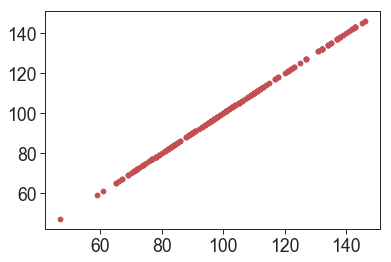

In [74]:
stats.spearmanr(result_fit.predict(features), response.loc[:, outcome])
plt.plot(result_fit.predict(features), 
         response.loc[:, outcome], 'ro')

In [52]:
from matplotlib import gridspec
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
import matplotlib.lines as mlines
import matplotlib.patches as patches
import matplotlib.mlab as mlab
import matplotlib.animation as animation
from mpl_toolkits.axes_grid1 import make_axes_locatable

def plot_ortho(image, overlay=None, reorient=True, blend=False,
    # xyz arguments
    xyz=None, xyz_lines=True, xyz_color='red', xyz_alpha=0.6, xyz_linewidth=2, xyz_pad=5,
    orient_labels=True,
    # base image arguments
    alpha=1, cmap='Greys_r',
    # overlay arguments
    overlay_cmap='jet', overlay_alpha=0.9,
    # background arguments
    black_bg=True, bg_thresh_quant=0.01, bg_val_quant=0.99,
    # scale/crop/domain arguments
    crop=False, scale=False, domain_image_map=None,
    # title arguments
    title=None, titlefontsize=24, title_dx=0, title_dy=0,
    # 4th panel text arguemnts
    text=None, textfontsize=24, textfontcolor='white', text_dx=0, text_dy=0,
    # save & size arguments
    filename=None, dpi=500, figsize=1., flat=False, transparent=True):
    """
    Plot an orthographic view of a 3D image

    TODO:
        - add colorbar option

    ANTsR function: N/A

    Arguments
    ---------
    image : ANTsImage
        image to plot

    overlay : ANTsImage
        image to overlay on base image

    slices : list or tuple of 3 integers
        slice indices along each axis to plot
        This can be absolute array indices (e.g. (80,100,120)), or
        this can be relative array indices (e.g. (0.4,0.5,0.6)).
        The default is to take the middle slice along each axis.

    xyz : list or tuple of 3 integers
        if given, solid lines will be drawn to converge at this coordinate.
        This is useful for pinpointing a specific location in the image.

    flat : boolean
        if true, the ortho image will be plot in one row
        if false, the ortho image will be a 2x2 grid with the bottom
            left corner blank

    cmap : string
        colormap to use for base image. See matplotlib.

    overlay_cmap : string
        colormap to use for overlay images, if applicable. See matplotlib.

    overlay_alpha : float
        level of transparency for any overlays. Smaller value means
        the overlay is more transparent. See matplotlib.

    axis : integer
        which axis to plot along if image is 3D

    black_bg : boolean
        if True, the background of the image(s) will be black.
        if False, the background of the image(s) will be determined by the
            values `bg_thresh_quant` and `bg_val_quant`.

    bg_thresh_quant : float
        if white_bg=True, the background will be determined by thresholding
        the image at the `bg_thresh` quantile value and setting the background
        intensity to the `bg_val` quantile value.
        This value should be in [0, 1] - somewhere around 0.01 is recommended.
            - equal to 1 will threshold the entire image
            - equal to 0 will threshold none of the image

    bg_val_quant : float
        if white_bg=True, the background will be determined by thresholding
        the image at the `bg_thresh` quantile value and setting the background
        intensity to the `bg_val` quantile value.
        This value should be in [0, 1]
            - equal to 1 is pure white
            - equal to 0 is pure black
            - somewhere in between is gray

    domain_image_map : ANTsImage
        this input ANTsImage or list of ANTsImage types contains a reference image
        `domain_image` and optional reference mapping named `domainMap`.
        If supplied, the image(s) to be plotted will be mapped to the domain
        image space before plotting - useful for non-standard image orientations.

    crop : boolean
        if true, the image(s) will be cropped to their bounding boxes, resulting
        in a potentially smaller image size.
        if false, the image(s) will not be cropped

    scale : boolean or 2-tuple
        if true, nothing will happen to intensities of image(s) and overlay(s)
        if false, dynamic range will be maximized when visualizing overlays
        if 2-tuple, the image will be dynamically scaled between these quantiles

    title : string
        add a title to the plot

    filename : string
        if given, the resulting image will be saved to this file

    dpi : integer
        determines resolution of image if saved to file. Higher values
        result in higher resolution images, but at a cost of having a
        larger file size

    Example
    -------
    >>> import ants
    >>> mni = ants.image_read(ants.get_data('mni'))
    >>> ants.plot_ortho(mni, xyz=(100,100,100))
    >>> mni2 = mni.threshold_image(7000, mni.max())
    >>> ants.plot_ortho(mni, overlay=mni2)
    >>> ants.plot_ortho(mni, overlay=mni2, flat=True)
    >>> ants.plot_ortho(mni, overlay=mni2, xyz=(110,110,110), xyz_lines=False,
                        text='Lines Turned Off', textfontsize=22)
    >>> ants.plot_ortho(mni, mni2, xyz=(120,100,100),
                        text=' Example \nOrtho Text', textfontsize=26,
                        title='Example Ortho Title', titlefontsize=26)
    """
    import warnings
    def mirror_matrix(x):
        return x[::-1,:]
    def rotate270_matrix(x):
        return mirror_matrix(x.T)
    def reorient_slice(x, axis):
        return rotate270_matrix(x)

    # need this hack because of a weird NaN warning from matplotlib with overlays
    warnings.simplefilter('ignore')

    # handle `image` argument
    if isinstance(image, str):
        image = ants.image_read(image)
    if not isinstance(image, ants.ANTsImage):
        raise ValueError('image argument must be an ANTsImage')
    if image.dimension != 3:
        raise ValueError('Input image must have 3 dimensions!')

    # handle `overlay` argument
    if overlay is not None:
        if isinstance(overlay, str):
            overlay = ants.image_read(overlay)
        if not isinstance(overlay, ants.ANTsImage):
            raise ValueError('overlay argument must be an ANTsImage')
        if overlay.dimension != 3:
            raise ValueError('Overlay image must have 3 dimensions!')

        if not ants.image_physical_space_consistency(image, overlay):
            overlay = reg.resample_image_to_target(overlay, image, interp_type='linear')

    if blend:
        if alpha == 1:
            alpha = 0.5
        image = image*alpha + overlay*(1-alpha)
        overlay = None
        alpha = 1.

    if image.pixeltype not in {'float', 'double'}:
        scale = False # turn off scaling if image is discrete

    # reorient images
    if reorient != False:
        if reorient == True:
            reorient = 'RPI'
        image = image.reorient_image2('RPI')
        if overlay is not None:
            overlay = overlay.reorient_image2('RPI')

    # handle `slices` argument
    if xyz is None:
        xyz = [int(s/2) for s in image.shape]
    for i in range(3):
        if xyz[i] is None:
            xyz[i] = int(image.shape[i]/2)

    # resample image if spacing is very unbalanced
    spacing = [s for i,s in enumerate(image.spacing)]
    if (max(spacing) / min(spacing)) > 3.:
        new_spacing = (1,1,1)
        image = image.resample_image(tuple(new_spacing))
        if overlay is not None:
            overlay = overlay.resample_image(tuple(new_spacing))
        xyz = [int(sl*(sold/snew)) for sl,sold,snew in zip(xyz,spacing,new_spacing)]

    # potentially crop image
    if crop:
        plotmask = image.get_mask(cleanup=0)
        if plotmask.max() == 0:
            plotmask += 1
        image = image.crop_image(plotmask)
        if overlay is not None:
            overlay = overlay.crop_image(plotmask)

    # pad images
    image, lowpad, uppad = image.pad_image(return_padvals=True)
    xyz = [v+l for v,l in zip(xyz,lowpad)]
    if overlay is not None:
        overlay = overlay.pad_image()

    # handle `domain_image_map` argument
    if domain_image_map is not None:
        if isinstance(domain_image_map, ants.ANTsImage):
            tx = tio2.new_ants_transform(precision='float', transform_type='AffineTransform',
                                         dimension=image.dimension)
            image = tio.apply_ants_transform_to_image(tx, image, domain_image_map)
            if overlay is not None:
                overlay = tio.apply_ants_transform_to_image(tx, overlay,
                                                            domain_image_map,
                                                            interpolation='linear')
        elif isinstance(domain_image_map, (list, tuple)):
            # expect an image and transformation
            if len(domain_image_map) != 2:
                raise ValueError('domain_image_map list or tuple must have length == 2')

            dimg = domain_image_map[0]
            if not isinstance(dimg, ants.ANTsImage):
                raise ValueError('domain_image_map first entry should be ANTsImage')

            tx = domain_image_map[1]
            image = reg.apply_transforms(dimg, image, transform_list=tx)
            if overlay is not None:
                overlay = reg.apply_transforms(dimg, overlay, transform_list=tx,
                                               interpolator='linear')

    ## single-channel images ##
    if image.components == 1:

        # potentially find dynamic range
        if scale == True:
            vmin, vmax = image.quantile((0.05,0.95))
        elif isinstance(scale, (list,tuple)):
            if len(scale) != 2:
                raise ValueError('scale argument must be boolean or list/tuple with two values')
            vmin, vmax = image.quantile(scale)
        else:
            vmin = None
            vmax = None

        if not flat:
            nrow = 2
            ncol = 2
        else:
            nrow = 1
            ncol = 3

        fig = plt.figure(figsize=(9*figsize,4*figsize))
        if title is not None:
            basey = 0.88 if not flat else 0.66
            basex = 0.5
            fig.suptitle(title, fontsize=56, x=0.5, y=0.80)

        gs = gridspec.GridSpec(nrow, ncol,
                 wspace=0.0, hspace=0.0,
                 top=1.-0.5/(nrow+1), bottom=0.5/(nrow+1),
                 left=0.5/(ncol+1), right=1-0.5/(ncol+1))

        # pad image to have isotropic array dimensions
        image = image.numpy()
        if overlay is not None:
            overlay = overlay.numpy()
            overlay[np.abs(overlay) == 0] = np.nan

        yz_slice = reorient_slice(image[xyz[0],:,:],0)
        ax = plt.subplot(gs[0,0])
        ax.imshow(yz_slice, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
        if overlay is not None:
            yz_overlay = reorient_slice(overlay[xyz[0],:,:],0)
            ax.imshow(yz_overlay, alpha=overlay_alpha, cmap=overlay_cmap, aspect='auto')
        if xyz_lines:
            # add lines
            l = mlines.Line2D([yz_slice.shape[0]-xyz[1],yz_slice.shape[0]-xyz[1]],
                              [xyz_pad,yz_slice.shape[0]-xyz_pad],
                              color=xyz_color, alpha=xyz_alpha, linewidth=xyz_linewidth)
            ax.add_line(l)
            l = mlines.Line2D([xyz_pad,yz_slice.shape[1]-xyz_pad],
                              [yz_slice.shape[1]-xyz[2],yz_slice.shape[1]-xyz[2]],
                color=xyz_color, alpha=xyz_alpha, linewidth=xyz_linewidth)
            ax.add_line(l)
        if orient_labels:
            ax.text(0.5,0.98, 'S',
                    horizontalalignment='center',
                    verticalalignment='top',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
            ax.text(0.5,0.02, 'I',
                    horizontalalignment='center',
                    verticalalignment='bottom',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
            ax.text(0.98,0.5, 'A',
                    horizontalalignment='right',
                    verticalalignment='center',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
            ax.text(0.02,0.5, 'P',
                    horizontalalignment='left',
                    verticalalignment='center',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
        ax.axis('off')

        xz_slice = reorient_slice(image[:,xyz[1],:],1)
        ax = plt.subplot(gs[0,1])
        ax.imshow(xz_slice, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
        if overlay is not None:
            xz_overlay = reorient_slice(overlay[:,xyz[1],:],1)
            ax.imshow(xz_overlay, alpha=overlay_alpha, cmap=overlay_cmap, aspect='auto')
        if xyz_lines:
            # add lines
            l = mlines.Line2D([xz_slice.shape[0]-xyz[0],xz_slice.shape[0]-xyz[0]],
                              [xyz_pad,xz_slice.shape[0]-xyz_pad],
                               color=xyz_color, alpha=xyz_alpha, linewidth=xyz_linewidth)
            ax.add_line(l)
            l = mlines.Line2D([xyz_pad,xz_slice.shape[1]-xyz_pad],
                              [xz_slice.shape[1]-xyz[2],xz_slice.shape[1]-xyz[2]],
                              color=xyz_color, alpha=xyz_alpha, linewidth=xyz_linewidth)
            ax.add_line(l)
        if orient_labels:
            ax.text(0.5,0.98, 'S',
                    horizontalalignment='center',
                    verticalalignment='top',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
            ax.text(0.5,0.02, 'I',
                    horizontalalignment='center',
                    verticalalignment='bottom',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
            ax.text(0.98,0.5, 'L',
                    horizontalalignment='right',
                    verticalalignment='center',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
            ax.text(0.02,0.5, 'R',
                    horizontalalignment='left',
                    verticalalignment='center',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
        ax.axis('off')

        xy_slice = reorient_slice(image[:,:,xyz[2]],2)
        if not flat:
            ax = plt.subplot(gs[1,1])
        else:
            ax = plt.subplot(gs[0,2])
        ax.imshow(xy_slice, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
        if overlay is not None:
            xy_overlay = reorient_slice(overlay[:,:,xyz[2]],2)
            im = ax.imshow(xy_overlay, alpha=overlay_alpha, cmap=overlay_cmap, aspect='auto')
            
            divider = make_axes_locatable(ax)
            cax = divider.append_axes("right", size="5%", pad=0.05)     
            cb = plt.colorbar(im, cax=cax)          
            cb.ax.tick_params(labelsize=30)
            cb.set_label("Spearman Correlation", labelpad=-1, size=40)
            
        if xyz_lines:
            # add lines
            l = mlines.Line2D([xy_slice.shape[0]-xyz[0],xy_slice.shape[0]-xyz[0]],
                              [xyz_pad,xy_slice.shape[0]-xyz_pad],
                              color=xyz_color, alpha=xyz_alpha, linewidth=xyz_linewidth)
            ax.add_line(l)
            l = mlines.Line2D([xyz_pad,xy_slice.shape[1]-xyz_pad],
                              [xy_slice.shape[1]-xyz[1],xy_slice.shape[1]-xyz[1]],
                              color=xyz_color, alpha=xyz_alpha, linewidth=xyz_linewidth)
            ax.add_line(l)
        if orient_labels:
            ax.text(0.5,0.98, 'A',
                    horizontalalignment='center',
                    verticalalignment='top',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
            ax.text(0.5,0.02, 'P',
                    horizontalalignment='center',
                    verticalalignment='bottom',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
            ax.text(0.98,0.5, 'L',
                    horizontalalignment='right',
                    verticalalignment='center',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
            ax.text(0.02,0.5, 'R',
                    horizontalalignment='left',
                    verticalalignment='center',
                    fontsize=20*figsize, color=textfontcolor,
                    transform=ax.transAxes)
        ax.axis('off')

In [13]:
fsaverage = fetch_surf_fsaverage()
mesh = surface.load_surf_mesh(fsaverage['pial_right'])
surf_map = mesh[0][:, 0]
html = html_surface.view_surf(fsaverage['pial_right'], surf_map,
                               fsaverage['sulc_right'], '90%')
html

In [14]:
destrieux1 = datasets.fetch_atlas_surf_destrieux()['map_left']
html = html_surface.view_surf(
    fsaverage['pial_left'], destrieux1, symmetric_cmap=False)
html

In [218]:
html1 = html_surface.view_surf('../../software/dhcp-structural-pipeline/workdir/ALBERT_09-session1/surfaces/ALBERT_09-session1/workbench/ALBERT_09-session1.R.pial.native.surf.gii', black_bg=True)
html2 = html_surface.view_surf('../../software/dhcp-structural-pipeline/workdir/ALBERT_09-session1/surfaces/ALBERT_09-session1/workbench/ALBERT_09-session1.L.pial.native.surf.gii', black_bg=True)
html1

In [219]:
html2

In [220]:
def _make_connectome():
    adj = np.diag([1.5, .3, 2.5], 2)
    adj += adj.T
    adj += np.eye(5)

    coord = np.arange(5)
    coord = np.asarray([coord * 10, -coord, coord[::-1]]).T
    return adj, coord

adj, coord = _make_connectome()
html = html_connectome.view_connectome(adj, coord)
html

In [8]:
all_corrs = []
for j in response.columns:
    corrs = []
    for i in brain_markers.columns:
        corr = stats.spearmanr(brain_markers.loc[:, i], 
                               response.loc[:, j])
        corrs.append([i, j, corr[0], corr[1]])
    cor_df_j = pd.DataFrame(corrs)
    Z = cor_df_j.iloc[:, 3]
    %R -i Z -o W W = p.adjust(Z, 'fdr')
    cor_df_j.iloc[:, 3] = W
    all_corrs.append(cor_df_j)
all_corrs_raw = pd.concat(all_corrs, axis=0)
all_corrs= all_corrs_raw.loc[all_corrs_raw.iloc[:, 3] < 0.05, ]
all_corrs= all_corrs.pivot(index=0, columns=1, values=2)
all_corrs_raw.head()

,0,1,2,3
0,JAC_corpus callosum_left,Cognitive_12m,0.095893,0.993325
1,MD_corpus callosum_left,Cognitive_12m,0.049211,0.998530
2,ALFF_corpus callosum_left,Cognitive_12m,0.029589,0.998530
3,fALFF_corpus callosum_left,Cognitive_12m,0.015117,0.998530
4,ReHo_corpus callosum_left,Cognitive_12m,-0.294069,0.004875


In [9]:
jhu_annotations = pd.read_csv('../../data/Atlas/jhu_atlas_neonate/label_JHU-neonate-SS_seg.csv', header=None)
jhu_annotations_dict = {}
jhu_annotations_dict2 = {}
template_b0 = ants.image_read('results/processed/sub-143_T1w_noise_corrected_reoriented_enh_b0.nii.gz')
template_mask = template_b0.get_mask()
jhu_atlas = ants.image_read('results/template/JHU_Atlas_JHU_neonate_SS_122parcellation.nii.gz')
jhu_mat = ants.images_to_matrix([jhu_atlas], template_mask)

albert06 = ants.image_read('results/ALBERTs/ALBERT_06-session1/T2/ALBERT_06-session1.nii.gz')
albert06_mask = albert06.get_mask()
jhu_atlas2 = ants.image_read('results/template/ALBERT_06_warp_to_JHU_JHU_neonate_SS_122parcellation.nii.gz')
jhu_mat2 = ants.images_to_matrix([jhu_atlas2], albert06_mask)

for i in range(jhu_annotations.shape[0]):
    jhu_annotations_dict[jhu_annotations.iloc[i, 0]] = '_'.join(jhu_annotations.iloc[i, 1:-1].tolist())
    jhu_annotations_dict2['_'.join(jhu_annotations.iloc[i, 1:-1].tolist())] = jhu_annotations.iloc[i, 0]    
native_modalities = ['tissue_label', 'b0', 't1', 
                     'alff', 'falff', 'reho', 
                     'fa', 'md', 
                     'od', 'icvf', 'isovf']
templates = []
for t in native_modalities:
    templates.append(ants.image_read(glob.glob(f'{t}_mean_template.nii.gz')[0]))

all_corrs_colname_roi_num = [jhu_annotations_dict2[i] for i in all_corrs.index.map(lambda x: x.split('_', 1)[1])]
all_corrs_modals = [ i for i in all_corrs.index.map(lambda x: x.split('_', 1)[0])]
all_corrs = all_corrs.fillna(0)
all_corrs.loc[all_corrs.index.str.contains("ICVF"), :]
all_corrs.shape
modal_activate = {}
for modal_outcome in all_corrs.columns:
    modal_activate[modal_outcome] = {}    
    for col, modal, roi in zip(all_corrs.index, all_corrs_modals, all_corrs_colname_roi_num):
        modal_activate[modal_outcome][modal] = modal_activate[modal_outcome].get(modal, 0) + (jhu_mat == roi)*all_corrs.loc[col, modal_outcome]        
    for modal in np.unique(all_corrs_modals):
        if (modal_activate[modal_outcome][modal] == 0).all(): print(modal_activate[modal_outcome][modal])
        modal_activate[modal_outcome][modal] = ants.matrix_to_images(modal_activate[modal_outcome][modal], 
                                                                     template_mask)[0].crop_image(template_mask)  


[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]


## ants package plot_ortho needs manual tweaking the xyx lines, not good

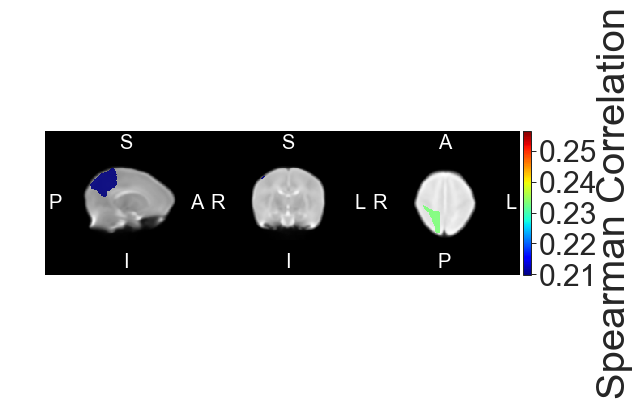

In [136]:
plot_ortho(templates[1], overlay=modal_activate['Cognitive_18m']['JAC'], xyz=(90,100,80), xyz_lines=False,
           text='Lines Turned Off',  flat=True)

## using nilearn

In [149]:
print(modal_outcome, modal)
plotting.view_img(ants.to_nibabel(modal_activate[modal_outcome][modal]), 
                          bg_img=ants.to_nibabel(templates[1].crop_image(template_mask)))

Receptive Communication_12m fALFF


In [11]:
all_corrs.to_csv("SuppFig1_whole_brain_spearman.csv")

/home/qinqian/.local/lib/python3.6/site-packages/matplotlib/cbook/deprecation.py:106: MatplotlibDeprecationWarning: Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.
  warnings.warn(message, mplDeprecation, stacklevel=1)


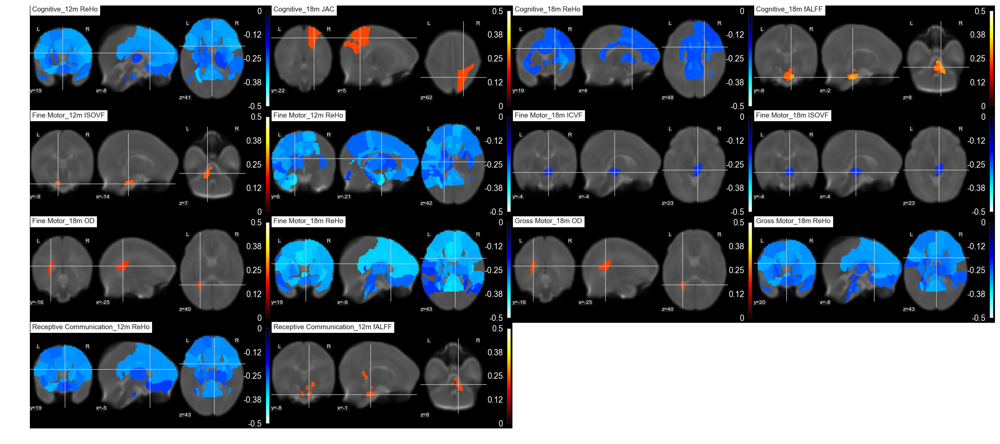

In [12]:
template_over = templates[1].crop_image(template_mask)
gs = gridspec.GridSpec(5, 4,
         wspace=0.0, hspace=0.0,
         top=1.-0.5/(4+1), bottom=0.5/(4+1),
         left=0.5/(5+1), right=1-0.5/(5+1))
n = 0
fig = plt.figure(figsize=(35, 20))
for modal_outcome in all_corrs.columns:
    for modal in np.unique(all_corrs_modals):
        axes = plt.subplot(gs[n])
        if modal_activate[modal_outcome][modal].sum() == 0: 
            continue
        n += 1
        
#         plot_ortho(templates[1], modal_activate[modal_outcome][modal], overlay_alpha=.5, figsize=5,
#                    title="%s %s" %(modal_outcome, modal), flat=True)

        plotting.plot_stat_map(ants.to_nibabel(modal_activate[modal_outcome][modal]), vmax=0.5,
                               title="%s %s" %(modal_outcome, modal), figure=fig, axes=axes,
                               bg_img=ants.to_nibabel(template_over))
    
plt.savefig('SuppFig1.pdf')

## TSB group and Bayley assocation with brain markers

In [13]:
all_corrs_medium = []
for j in response.columns:
    corrs = []
    for i in brain_markers.columns:
        corr = stats.spearmanr(brain_markers.loc[(final.loc[:, 'Peak-TSB']>15) & (final.loc[:, 'Peak-TSB']<=20), i], 
                               response.loc[(final.loc[:, 'Peak-TSB']>15) & (final.loc[:, 'Peak-TSB']<=20), j])
        corrs.append([i, j, corr[0], corr[1]])
    cor_df_j = pd.DataFrame(corrs)
    Z = cor_df_j.iloc[:, 3]
    %R -i Z -o W W = p.adjust(Z, 'fdr')
    cor_df_j.iloc[:, 3] = W
    all_corrs_medium.append(cor_df_j)
all_corrs_medium = pd.concat(all_corrs_medium, axis=0)

In [14]:
all_corrs_severe = []
for j in response.columns:
    corrs = []
    for i in brain_markers.columns:
        corr = stats.spearmanr(brain_markers.loc[(final.loc[:, 'Peak-TSB']>20), i], 
                               response.loc[(final.loc[:, 'Peak-TSB']>20), j])
        corrs.append([i, j, corr[0], corr[1]])
    cor_df_j = pd.DataFrame(corrs)
    Z = cor_df_j.iloc[:, 3]
    %R -i Z -o W W = p.adjust(Z, 'fdr')
    cor_df_j.iloc[:, 3] = W
    all_corrs_severe.append(cor_df_j)
all_corrs_severe = pd.concat(all_corrs_severe, axis=0)

In [15]:
filter_all_corrsm= all_corrs_medium.loc[all_corrs_medium.iloc[:, 3] < 0.05, ]
filter_all_corrsm= filter_all_corrsm.pivot(index=0, columns=1, values=2)

filter_all_corrss = all_corrs_severe.loc[all_corrs_severe.iloc[:, 3] < 0.05, ]
filter_all_corrss = filter_all_corrss.pivot(index=0, columns=1, values=2)

In [16]:
filter_all_corrsm.columns = ['Medium Receptive Communication_12m']
filter_all_corrss.columns = ['Severe Fine Motor_12m', 'Severe Fine Motor_18m']

In [17]:
filter_all_corrsms = filter_all_corrsm.merge(filter_all_corrss, left_index=True, right_index=True, how='outer')
filter_all_corrsms_colname_roi_num = [jhu_annotations_dict2[i] for i in filter_all_corrsms.index.map(lambda x: x.split('_', 1)[1])]
filter_all_corrsms_modals = [ i for i in filter_all_corrsms.index.map(lambda x: x.split('_', 1)[0])]
filter_all_corrsms = filter_all_corrsms.fillna(0)

In [18]:
filter_all_corrsms.head()
filter_all_corrsms.loc[filter_all_corrsms.index.str.contains('ISOVF'), ]

,Medium Receptive Communication_12m,Severe Fine Motor_12m,Severe Fine Motor_18m
0,,,
ISOVF_middle cerebellar peduncle_left,0.0,0.319402,0.0


In [20]:
def draw_brain_statmap(filter_all_corrsms):
    filter_all_corrsms_colname_roi_num = [jhu_annotations_dict2[i] for i in filter_all_corrsms.index.map(lambda x: x.split('_', 1)[1])]
    filter_all_corrsms_modals = [ i for i in filter_all_corrsms.index.map(lambda x: x.split('_', 1)[0])]
    filter_all_corrsms = filter_all_corrsms.fillna(0)
    filter_all_modal_activate = {}

    for modal_outcome in filter_all_corrsms.columns:
        filter_all_modal_activate[modal_outcome] = {}  

        for col, modal, roi in zip(filter_all_corrsms.index, filter_all_corrsms_modals, filter_all_corrsms_colname_roi_num):
            filter_all_modal_activate[modal_outcome][modal] = filter_all_modal_activate[modal_outcome].get(modal, 0) + (jhu_mat == roi)*filter_all_corrsms.loc[col, modal_outcome]

        for modal in np.unique(filter_all_corrsms_modals):
            if (filter_all_modal_activate[modal_outcome][modal] == 0).all(): print(filter_all_modal_activate[modal_outcome][modal])
            filter_all_modal_activate[modal_outcome][modal] = ants.matrix_to_images(filter_all_modal_activate[modal_outcome][modal], 
                                                                                    template_mask)[0].crop_image(template_mask)

    template_over = templates[1].crop_image(template_mask)
    gs = gridspec.GridSpec(2, 3,
             wspace=0.0, hspace=0.0,
             top=1.-0.5/(4+1), bottom=0.5/(4+1),
             left=0.5/(5+1), right=1-0.5/(5+1))
    n = 0
    fig = plt.figure(figsize=(35, 14))
    for modal_outcome in filter_all_corrsms.columns:
        for modal in np.unique(filter_all_corrsms_modals):
            axes = plt.subplot(gs[n])
            if filter_all_modal_activate[modal_outcome][modal].sum() == 0: 
                continue
            n += 1
            plotting.plot_stat_map(ants.to_nibabel(filter_all_modal_activate[modal_outcome][modal]), vmax=1,
                                   title="%s %s" %(modal_outcome, modal), figure=fig, axes=axes,
                                   bg_img=ants.to_nibabel(template_over))

    plt.savefig('SuppFig2_TSB.pdf')    
    
    
#draw_brain_statmap(filter_all_corrsms)
filter_all_corrsms.to_csv('SuppFig2_TSB_spearman.csv')

## Preterm group and brain markers

In [21]:
all_corrs_preterm = []
for j in response.columns:
    corrs = []
    for i in brain_markers.columns:
        corr = stats.spearmanr(brain_markers.loc[(final.GA<35), i], 
                               response.loc[(final.GA<35), j])
        corrs.append([i, j, corr[0], corr[1]])
    cor_df_j = pd.DataFrame(corrs)
    Z = cor_df_j.iloc[:, 3]
    %R -i Z -o W W = p.adjust(Z, 'fdr')
    cor_df_j.iloc[:, 3] = W
    all_corrs_preterm.append(cor_df_j)
    
all_corrs_preterm = pd.concat(all_corrs_preterm, axis=0)

In [22]:
all_corrs_term = []
for j in response.columns:
    corrs = []
    for i in brain_markers.columns:
        corr = stats.spearmanr(brain_markers.loc[(final.GA>=35), i],
                               response.loc[(final.GA>=35), j])
        corrs.append([i, j, corr[0], corr[1]])
    cor_df_j = pd.DataFrame(corrs)
    Z = cor_df_j.iloc[:, 3]
    %R -i Z -o W W = p.adjust(Z, 'fdr')
    cor_df_j.iloc[:, 3] = W
    all_corrs_term.append(cor_df_j)
    
all_corrs_term = pd.concat(all_corrs_term, axis=0)

In [23]:
filter_all_corrsp = all_corrs_preterm.loc[all_corrs_preterm.iloc[:, 3] < 0.05, ]
filter_all_corrsp = filter_all_corrsp.pivot(index=0, columns=1, values=2)

filter_all_corrst = all_corrs_term.loc[all_corrs_term.iloc[:, 3] < 0.05, ]
filter_all_corrst = filter_all_corrst.pivot(index=0, columns=1, values=2)

In [24]:
filter_all_corrst.shape, filter_all_corrsp.shape

((86, 4), (38, 3))

In [25]:
filter_all_corrsp.columns = ['Preterm Cognitive_12m', 'Preterm Fine Motor_18m', 'Preterm Gross Motor_18m']
filter_all_corrst.columns = ['(Near) term Expressive Communication_12m', '(Near) term Fine Motor_12m', 
                             '(Near) term Fine Motor_18m', '(Near) term Receptive Communication_12m']

In [26]:
filter_all_corrspt = filter_all_corrsp.merge(filter_all_corrst, left_index=True, right_index=True, how='outer')
filter_all_corrspt.columns

Index(['Preterm Cognitive_12m', 'Preterm Fine Motor_18m',
       'Preterm Gross Motor_18m', '(Near) term Expressive Communication_12m',
       '(Near) term Fine Motor_12m', '(Near) term Fine Motor_18m',
       '(Near) term Receptive Communication_12m'],
      dtype='object')

In [ ]:
plt.figure(figsize=(6, 36))
sns.heatmap(filter_all_corrspt, annot=True, cmap="YlGnBu", cbar=False)
# sns.heatmap(filter_all_corrst, annot=True, cmap="YlGnBu", ax=ax2)
# plt.tight_layout()
# plt.savefig('Fig3_preterm.pdf')

[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]


/home/qinqian/.local/lib/python3.6/site-packages/matplotlib/cbook/deprecation.py:106: MatplotlibDeprecationWarning: Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.
  warnings.warn(message, mplDeprecation, stacklevel=1)


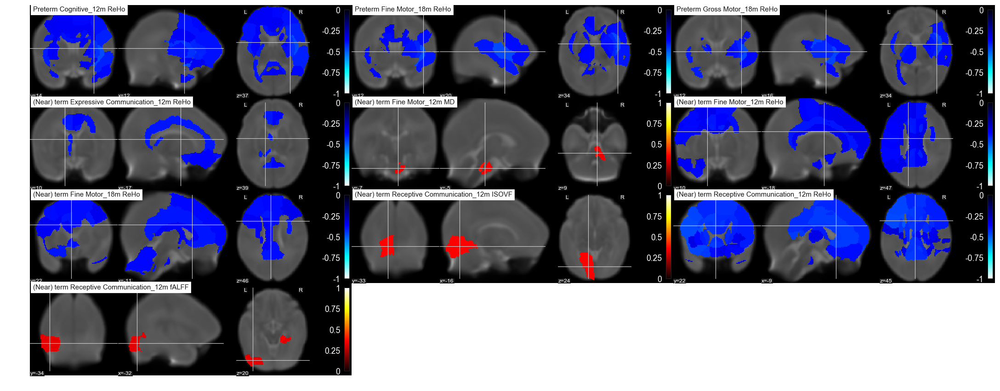

In [27]:
def draw_brain_statmap(filter_all_corrsms):
    filter_all_corrsms_colname_roi_num = [jhu_annotations_dict2[i] for i in filter_all_corrsms.index.map(lambda x: x.split('_', 1)[1])]
    filter_all_corrsms_modals = [ i for i in filter_all_corrsms.index.map(lambda x: x.split('_', 1)[0])]
    filter_all_corrsms = filter_all_corrsms.fillna(0)
    filter_all_modal_activate = {}

    for modal_outcome in filter_all_corrsms.columns:
        filter_all_modal_activate[modal_outcome] = {}  

        for col, modal, roi in zip(filter_all_corrsms.index, filter_all_corrsms_modals, filter_all_corrsms_colname_roi_num):
            filter_all_modal_activate[modal_outcome][modal] = filter_all_modal_activate[modal_outcome].get(modal, 0) + (jhu_mat == roi)*filter_all_corrsms.loc[col, modal_outcome]

        for modal in np.unique(filter_all_corrsms_modals):
            if (filter_all_modal_activate[modal_outcome][modal] == 0).all(): print(filter_all_modal_activate[modal_outcome][modal])
            filter_all_modal_activate[modal_outcome][modal] = ants.matrix_to_images(filter_all_modal_activate[modal_outcome][modal], 
                                                                                    template_mask)[0].crop_image(template_mask)

    template_over = templates[1].crop_image(template_mask)
    gs = gridspec.GridSpec(4, 3,
             wspace=0.0, hspace=0.0,
             top=1.-0.5/(4+1), bottom=0.5/(4+1),
             left=0.5/(5+1), right=1-0.5/(5+1))
    n = 0
    fig = plt.figure(figsize=(35, 14))
    for modal_outcome in filter_all_corrsms.columns:
        for modal in np.unique(filter_all_corrsms_modals):
            axes = plt.subplot(gs[n])
            if filter_all_modal_activate[modal_outcome][modal].sum() == 0: 
                continue
            n += 1
            plotting.plot_stat_map(ants.to_nibabel(filter_all_modal_activate[modal_outcome][modal]), vmax=1,
                                   title="%s %s" %(modal_outcome, modal), figure=fig, axes=axes,
                                   bg_img=ants.to_nibabel(template_over))

    plt.savefig('SuppFig3.pdf')    
    
draw_brain_statmap(filter_all_corrspt)
filter_all_corrspt.to_csv("SuppFig3_spearman.csv")

## Peak-TSB and GA Groups

In [28]:
all_corrs1 = []
for j in response.columns:
    corrs = []
    for i in brain_markers.columns:
        corr = stats.spearmanr(brain_markers.loc[(final.GA<35) & (final.loc[:, 'Peak-TSB']>15) & (final.loc[:, 'Peak-TSB']<=20), i], 
                               response.loc[(final.GA<35) & (final.loc[:, 'Peak-TSB']>15) & (final.loc[:, 'Peak-TSB']<=20), j])
        corrs.append([i, j, corr[0], corr[1]])
    cor_df_j = pd.DataFrame(corrs)
    Z = cor_df_j.iloc[:, 3]
    %R -i Z -o W W = p.adjust(Z, 'fdr')
    cor_df_j.iloc[:, 3] = W
    all_corrs1.append(cor_df_j)
    
all_corrs1 = pd.concat(all_corrs1, axis=0)

In [29]:
all_corrs2 = []
for j in response.columns:
    corrs = []
    for i in brain_markers.columns:
        corr = stats.spearmanr(brain_markers.loc[(final.GA<35) & (final.loc[:, 'Peak-TSB']>20), i], 
                               response.loc[(final.GA<35) & (final.loc[:, 'Peak-TSB']>20), j])
        corrs.append([i, j, corr[0], corr[1]])
    cor_df_j = pd.DataFrame(corrs)
    Z = cor_df_j.iloc[:, 3]
    %R -i Z -o W W = p.adjust(Z, 'fdr')
    cor_df_j.iloc[:, 3] = W
    all_corrs2.append(cor_df_j)
    
all_corrs2 = pd.concat(all_corrs2, axis=0)

In [30]:
all_corrs3 = []
for j in response.columns:
    corrs = []
    for i in brain_markers.columns:
        corr = stats.spearmanr(brain_markers.loc[(final.GA>=35) & (final.loc[:, 'Peak-TSB']>20), i],
                               response.loc[(final.GA>=35) & (final.loc[:, 'Peak-TSB']>20), j])
        corrs.append([i, j, corr[0], corr[1]])
    cor_df_j = pd.DataFrame(corrs)
    Z = cor_df_j.iloc[:, 3]
    %R -i Z -o W W = p.adjust(Z, 'fdr')
    cor_df_j.iloc[:, 3] = W
    all_corrs3.append(cor_df_j)
    
all_corrs3 = pd.concat(all_corrs3, axis=0)

In [31]:
all_corrs4 = []
for j in response.columns:
    corrs = []
    for i in brain_markers.columns:
        corr = stats.spearmanr(brain_markers.loc[(final.GA>=35) & (final.loc[:, 'Peak-TSB']>15) & (final.loc[:, 'Peak-TSB']<=20), i], 
                               response.loc[(final.GA>=35) & (final.loc[:, 'Peak-TSB']>15) & (final.loc[:, 'Peak-TSB']<=20), j])
        corrs.append([i, j, corr[0], corr[1]])
    cor_df_j = pd.DataFrame(corrs)
    Z = cor_df_j.iloc[:, 3]
    %R -i Z -o W W = p.adjust(Z, 'fdr')
    cor_df_j.iloc[:, 3] = W
    all_corrs4.append(cor_df_j)
    
all_corrs4 = pd.concat(all_corrs4, axis=0)

In [32]:
filter_all_corrs1 = all_corrs1.loc[all_corrs1.iloc[:, 3] < 0.05, ]
filter_all_corrs1 = filter_all_corrs1.pivot(index=0, columns=1, values=2)
filter_all_corrs2 = all_corrs2.loc[all_corrs2.iloc[:, 3] < 0.05, ]
filter_all_corrs2 = filter_all_corrs2.pivot(index=0, columns=1, values=2)
filter_all_corrs3 = all_corrs3.loc[all_corrs3.iloc[:, 3] < 0.05, ]
filter_all_corrs3 = filter_all_corrs3.pivot(index=0, columns=1, values=2)
filter_all_corrs4 = all_corrs4.loc[all_corrs4.iloc[:, 3] < 0.05, ]
filter_all_corrs4 = filter_all_corrs4.pivot(index=0, columns=1, values=2)

In [33]:
filter_all_corrs1.shape, filter_all_corrs2.shape

((11, 1), (0, 0))

In [34]:
filter_all_corrs4.shape, filter_all_corrs3.shape

((1, 1), (14, 3))

In [35]:
filter_all_corrs1_p = filter_all_corrs1.merge(filter_all_corrs2, left_index=True, right_index=True, how='outer')

In [36]:
filter_all_corrs1_p.columns = list(map(lambda x: "Preterm Medium TSB %s"%x, filter_all_corrs1_p.columns))

In [37]:
filter_all_corrs4_t = filter_all_corrs4.merge(filter_all_corrs3, 
                                              left_index=True, right_index=True, how='outer')

In [38]:
filter_all_corrs4_t.columns = ['(Near) term Medium TSB Fine Motor_18m', '(Near) term Severe TSB Cognitive_18m', 
 '(Near) term Severe Expressive Communication_12m', '(Near) term Fine Motor_12m']

In [39]:
filter_all_corrs1_pt = filter_all_corrs1_p.merge(filter_all_corrs4_t, left_index=True, right_index=True, how='outer')

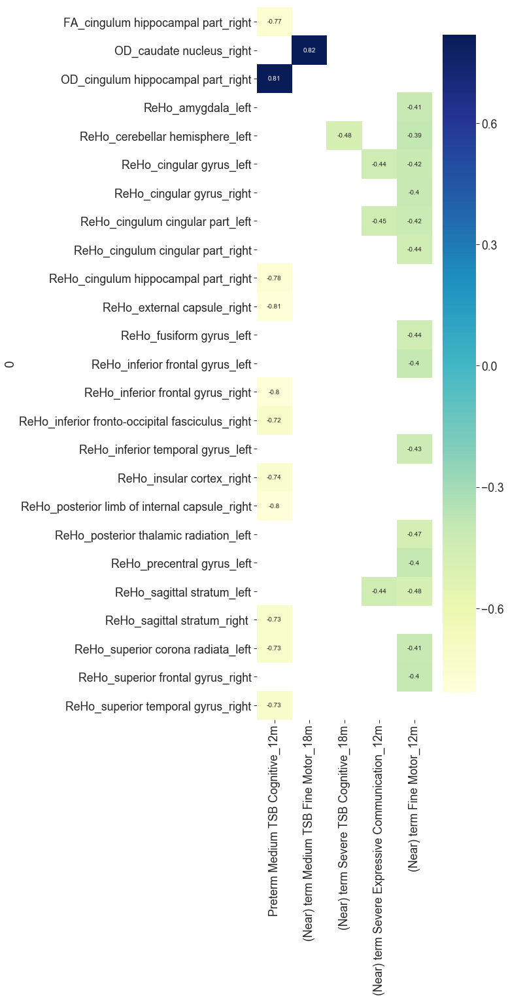

In [215]:
#f, (ax1, ax2) = plt.subplots(2, 1, gridspec_kw=grid_kws, figsize=(12,280))
grid_kws = {"height_ratios": [.45], "width_ratios": [.8], "hspace": .6}
f, (ax1) = plt.subplots(1, 1, gridspec_kw=grid_kws, figsize=(6, 20))
sns.heatmap(filter_all_corrs1_pt, annot=True, cmap="YlGnBu", ax=ax1)
plt.tight_layout()
# sns.heatmap(filter_all_corrs2, annot=True, cmap="YlGnBu", ax=ax1)
# plt.tight_layout()
# sns.heatmap(filter_all_corrs4, annot=True, cmap="YlGnBu", ax=ax2)
# plt.tight_layout()

[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]
[[0. 0. 0. ... 0. 0. 0.]]


/home/qinqian/.local/lib/python3.6/site-packages/matplotlib/cbook/deprecation.py:106: MatplotlibDeprecationWarning: Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.
  warnings.warn(message, mplDeprecation, stacklevel=1)


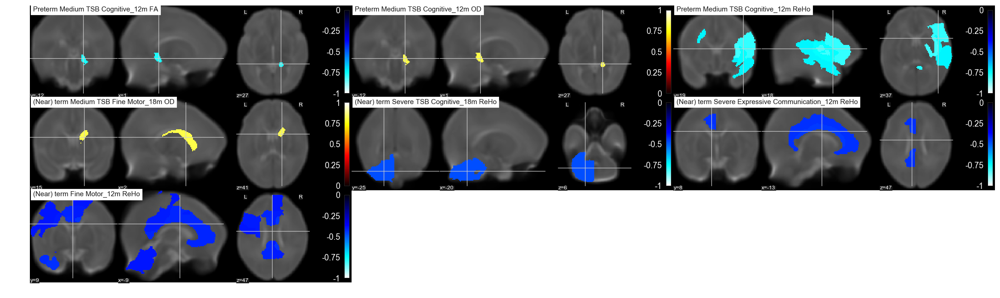

In [40]:
def draw_brain_statmap(filter_all_corrsms):
    filter_all_corrsms_colname_roi_num = [jhu_annotations_dict2[i] for i in filter_all_corrsms.index.map(lambda x: x.split('_', 1)[1])]
    filter_all_corrsms_modals = [ i for i in filter_all_corrsms.index.map(lambda x: x.split('_', 1)[0])]
    filter_all_corrsms = filter_all_corrsms.fillna(0)
    filter_all_modal_activate = {}

    for modal_outcome in filter_all_corrsms.columns:
        filter_all_modal_activate[modal_outcome] = {}  

        for col, modal, roi in zip(filter_all_corrsms.index, filter_all_corrsms_modals, filter_all_corrsms_colname_roi_num):
            filter_all_modal_activate[modal_outcome][modal] = filter_all_modal_activate[modal_outcome].get(modal, 0) + (jhu_mat == roi)*filter_all_corrsms.loc[col, modal_outcome]

        for modal in np.unique(filter_all_corrsms_modals):
            if (filter_all_modal_activate[modal_outcome][modal] == 0).all(): print(filter_all_modal_activate[modal_outcome][modal])
            filter_all_modal_activate[modal_outcome][modal] = ants.matrix_to_images(filter_all_modal_activate[modal_outcome][modal], 
                                                                                    template_mask)[0].crop_image(template_mask)

    template_over = templates[1].crop_image(template_mask)
    gs = gridspec.GridSpec(4, 3,
             wspace=0.0, hspace=0.0,
             top=1.-0.5/(4+1), bottom=0.5/(4+1),
             left=0.5/(5+1), right=1-0.5/(5+1))
    n = 0
    fig = plt.figure(figsize=(35, 14))
    for modal_outcome in filter_all_corrsms.columns:
        for modal in np.unique(filter_all_corrsms_modals):
            axes = plt.subplot(gs[n])
            if filter_all_modal_activate[modal_outcome][modal].sum() == 0: 
                continue
            n += 1
            plotting.plot_stat_map(ants.to_nibabel(filter_all_modal_activate[modal_outcome][modal]), vmax=1,
                                   title="%s %s" %(modal_outcome, modal), figure=fig, axes=axes,
                                   bg_img=ants.to_nibabel(template_over))

    plt.savefig('SuppFig4.pdf')    
    
draw_brain_statmap(filter_all_corrs1_pt)
filter_all_corrs1_pt.to_csv("SuppFig4_spearman.csv")

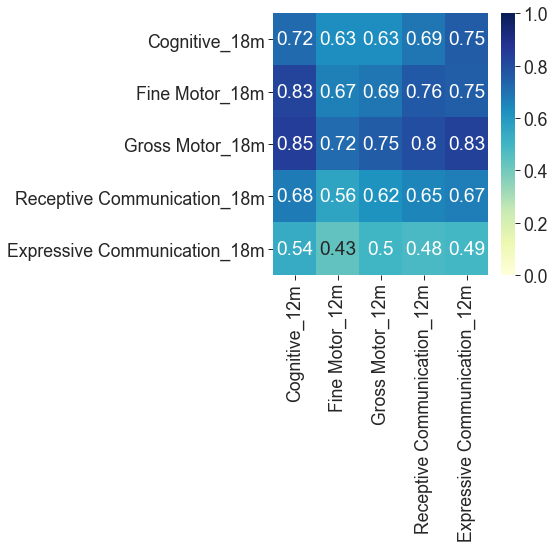

In [261]:
df = pd.DataFrame(0, columns=response.columns[response.columns.str.contains('12m')], 
                  index=response.columns[response.columns.str.contains('18m')])

for i in response.columns[response.columns.str.contains('12m')]:
    for j in response.columns[response.columns.str.contains('18m')]:
        co = stats.spearmanr(response.loc[:, i], response.loc[:, j])
        if co[1] <= 0.05:
            df.loc[j, i] = co[0]
        else:
            df.loc[j, i] = 0
plt.figure(figsize=[8, 8])   
sns.heatmap(df, annot=True, cmap="YlGnBu", cbar=True, vmin=0, vmax=1)
plt.tight_layout()
plt.savefig('Fig5_bayleylong_short.pdf')

## Stratified model analysis

In [263]:
performance_dfs = []
for seed in range(9000, 10000):    
    if os.path.exists(f'performances_jhu122_new_preterm_medium_{seed}_False.csv'):
        performance = pd.read_csv(f'performances_jhu122_new_preterm_medium_{seed}_False.csv')
        #performance.loc[:, 'seed'] = seed
        performance.loc[:, 'Time'] = performance.loc[:, 'Follow-up'].map(lambda x:x.split('_')[1])        
        performance.loc[:, 'Outcome'] = performance.loc[:, 'Follow-up'].map(lambda x:x.split('_')[0])
        #performance = performance.sort_values('Test ROCAUC', ascending=False)
        performance_dfs.append(performance)
df = pd.concat(performance_dfs, axis=0)
df2 =df.melt(id_vars=['Time', 'Outcome'], value_vars=df.columns[6:-2])
df.head()

,Unnamed: 0,Method,Follow-up,Parameter,Features,Mean Valid ROCAUC,Test ROCAUC,Test PRAUC,F1,Accuracy,Time,Outcome
0,0,LASSO,Cognitive_12m,All,FA_corpus callosum_left;MD_corpus callosum_rig...,1.0,0.459627,0.138751,0.000000,0.792453,12m,Cognitive
1,1,LASSO,Fine Motor_12m,All,ALFF_corpus callosum_left;fALFF_corpus callosu...,1.0,0.719444,0.340924,0.266667,0.792453,12m,Fine Motor
2,2,LASSO,Gross Motor_12m,All,MD_corpus callosum_left;ALFF_corpus callosum_l...,1.0,0.701863,0.309113,0.461538,0.867925,12m,Gross Motor
3,3,LASSO,Receptive Communication_12m,All,JAC_corpus callosum_left;FA_corpus callosum_le...,1.0,0.750000,0.477672,0.444444,0.905660,12m,Receptive Communication
4,4,LASSO,Expressive Communication_12m,All,FA_corpus callosum_left;OD_corpus callosum_lef...,1.0,0.654167,0.333617,0.250000,0.886792,12m,Expressive Communication


In [264]:
df.shape

(1920, 12)

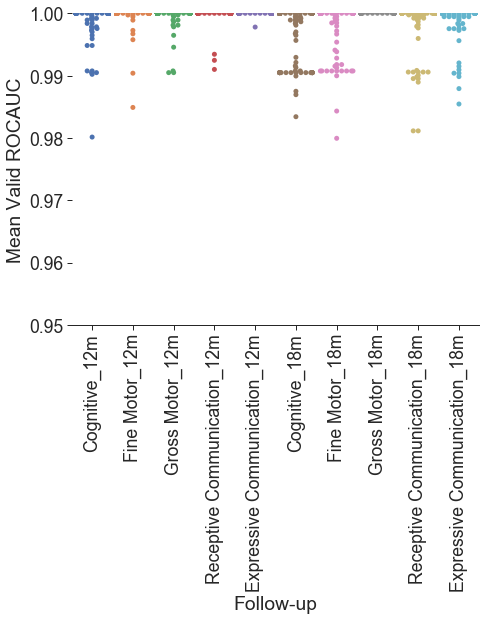

In [266]:
g = sns.catplot(y='Mean Valid ROCAUC', x='Follow-up', data=df, 
                sharey=True, aspect=0.8, 
                orient='v', kind='swarm', height=9)
(g.set_xticklabels(rotation=90)
 .set(ylim=(0.95, 1)).despine(left=True))
plt.tight_layout()
plt.savefig('Fig5_Valid.pdf')

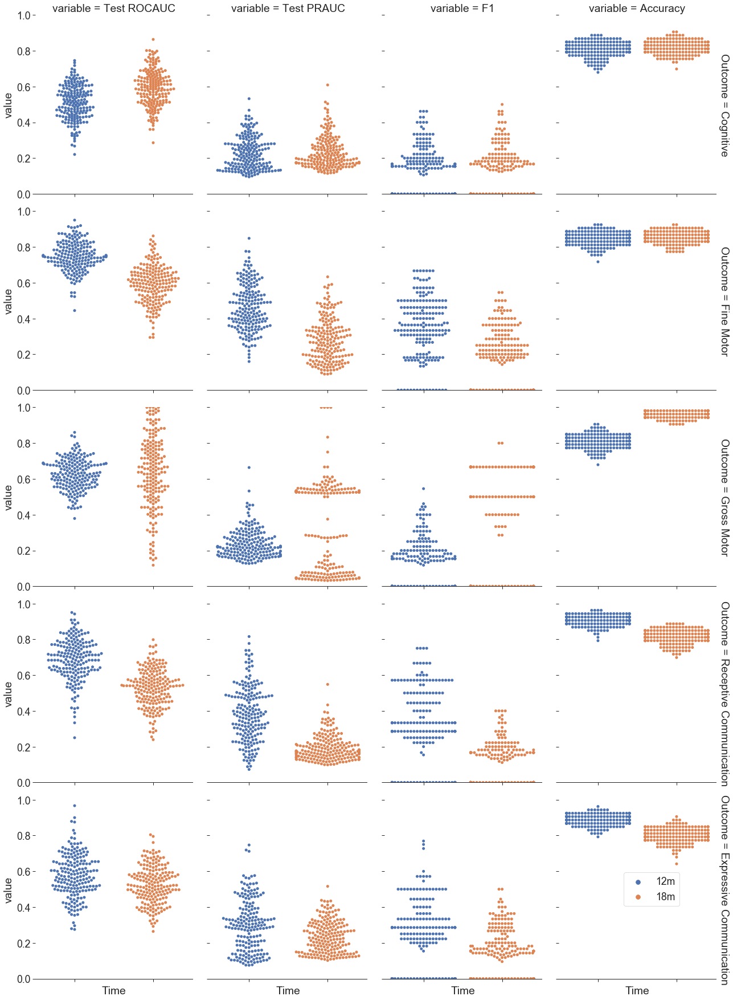

In [255]:
sns.set("paper", font_scale=2)
sns.set_style('ticks', {'font.family':'sans-serif', 'font.serif':'Helvetica'})
g = sns.catplot(y='value', x='Time', data=df2, col='variable', row='Outcome', 
                hue='Time',
                sharey=True, sharex=True, aspect=.9, legend=True, legend_out=True, #col_wrap=2,
                orient='v', kind='swarm', height=5, margin_titles=True)
(g.set_xticklabels(rotation=90) #.set_titles("{col_var}")
 .set(ylim=(0, 1)).despine(left=True)) # .set_titles("{col_name} {col_var}"))
##plt.tight_layout()
for a in g.axes[-1][-1:]:
    a.legend(loc='center right', bbox_to_anchor=(0.8, 0.5), ncol=1)

plt.savefig("Fig5_models_192seeds.pdf")

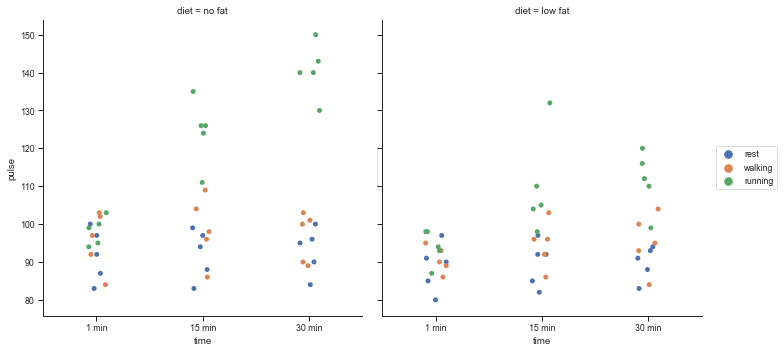

In [244]:
exercise = sns.load_dataset("exercise")
g = sns.catplot(x="time", y="pulse", hue="kind", legend=False,
                col="diet", data=exercise)
for a in g.axes:
    for i in a:
        i.legend(loc='center right', bbox_to_anchor=(1.25, 0.5), ncol=1)

## Model visualization

In [ ]:
import joblib
jhu_roi_outcome_model = pd.read_csv('jhu_roi_model_raw_fillna.csv', index_col=0)
features = np.array(jhu_roi_outcome_model.columns[:(9*122)].tolist() + ['preterm', 'GA', 'bw', 'sex', 'CGA', 'Peak-TSB'])
# model = joblib.load('LASSO_Gross Motor_18m_All_9999_False.pklz')
# (model.best_estimator_.named_steps['clf'].coef_ > 1e-8).sum()

In [13]:
model.best_params_
';'.join(list(features[(model.best_estimator_.named_steps['clf'].coef_ > 1e-8).ravel()]))

NameError: name 'model' is not defined

[NiftiLabelsMasker.fit_transform] loading data from results/template/sub-54_fengshi_bold_infant-neo-aal-3mm.nii
[Memory]    0.0s, 0.0min: Loading filter_and_extract...
__________________________________filter_and_extract cache loaded - 0.0s, 0.0min
(90, 90)


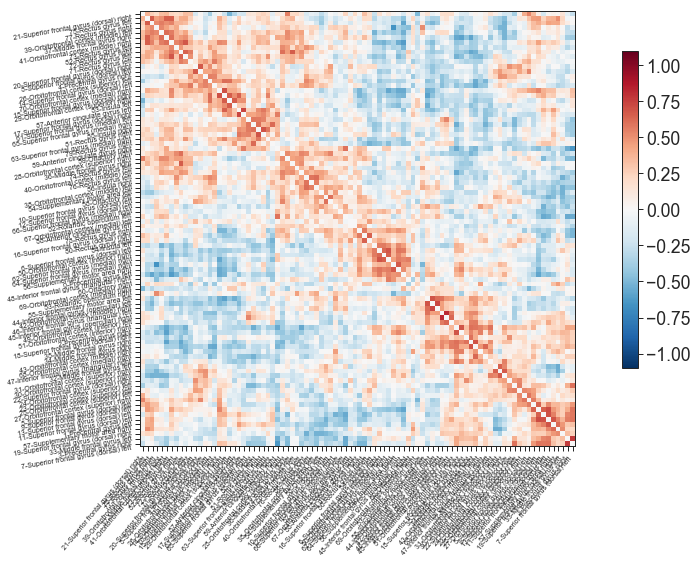

In [214]:
import nilearn
import nibabel as nib
from nilearn.input_data import NiftiLabelsMasker
from nilearn.connectome import ConnectivityMeasure
from nilearn import plotting
labels = pd.read_csv('../../data/Atlas/UNC-CEDARS-INFANT-20170420/labels.txt', sep='\t', header=None)
labels.sort_values(0, inplace=True)
neo_index = pd.read_table('/data1/qinqian/MRI/data/Atlas/UNC-CEDARS-INFANT-20170420/neo-index-conversion.txt', header=None)
label_dict = {}
for i in range(labels.shape[0]):
    label_dict[labels.iloc[i, 0]] = labels.iloc[i, 1]
neo_labels = []
for i, j in zip(neo_index.index, neo_index.iloc[:, 0]):
    neo_labels.append('%s-%s' %(i, label_dict[j]))
    
subject = 'sub-54'    
atlas_filename1 = f'results/template/{subject}_fengshi_bold_infant-neo-funPar-3mm.nii'
atlas_filename2 = f'results/template/{subject}_fengshi_bold_infant-neo-aal-3mm.nii'
bold = f'results/processed/{subject}_process_bold_clean4d.nii.gz'
masker = NiftiLabelsMasker(labels_img=atlas_filename2, standardize=True, memory='nilearn_cache', verbose=5)
time_series = masker.fit_transform(bold, confounds=None)
correlation_measure = ConnectivityMeasure(kind='correlation')
correlation_matrix = correlation_measure.fit_transform([time_series])[0]
np.fill_diagonal(correlation_matrix, 0)
print(correlation_matrix.shape)
plotting.plot_matrix(correlation_matrix, figure=(10, 8), labels=neo_labels, vmax=1.1, vmin=-1.1, reorder=True)